# Learning Probability Flows with Neural Networks
## Part 2 — Rectified Flow for a Two-Dimensional Boltzmann Distribution

**Method:** Rectified Flow — Liu, Gong & Liu (2022), *Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow* (1-rectified flow and one reflow step).

**Data:** Metropolis Monte Carlo — Frenkel & Smit, *Understanding Molecular Simulation*, §3.1–3.2.

**Abstract.** We sample the Boltzmann distribution $p(x) \propto e^{-V(x)/k_BT}$ of a particle in the tilted double-well potential
$V(x_0, x_1) = \varepsilon\,[\,c\,(x_0^2 - 1)^2 + (x_0 - x_1)^2 + d\,(x_0 + x_1)\,]$, $\varepsilon = 3,\ c = 1,\ d = 0.5$, with the Metropolis algorithm at $k_BT = 0.5,\ 1,\ 2$. The Monte Carlo configurations are the training data of a network $v_\theta(t, x)$ that learns the velocity field transporting $\mathcal N(0, I)$ into $p$ (1-rectified flow); one reflow step then straightens the paths (2-rectified flow). Samples are generated with a 4th-order Runge–Kutta scheme. Because this potential is separable, the exact distribution and the exact velocity field can be computed, so every result is checked against the truth. We study how sample and field quality depend on the temperature, the number of training samples, the number of RK4 steps and the placement of the time steps.

### Contents
1. Method I: Monte Carlo sampling of the Boltzmann distribution
   - 1.1 Goal · 1.2 Importance sampling · 1.3 Markov chains · 1.4 The Metropolis algorithm · 1.5 Practical points · 1.6 In short
2. Method II: Rectified Flow
   - 2.1 Goal · 2.2 Training · 2.3 What the network learns · 2.4 Why it works · 2.5 Reflow · 2.6 Straight paths need few steps · 2.7 In short
3. Setup
4. The model system
5. Metropolis Monte Carlo
6. Velocity network
7. Rectified Flow objective and training loop
8. RK4 ODE solver
9. Reflow pairs and straightness
10. Training
11. Results
    - 11.0 Evaluation setup · 11.1 Generated vs. target samples · 11.2 Trajectories · 11.3 Velocity field · 11.4 Number of RK4 steps · 11.5 Placement of the time steps · 11.6 Temperature · 11.7 Number of training samples
12. Discussion and conclusions
13. References

## 1. Method I: Monte Carlo sampling of the Boltzmann distribution

*Following Frenkel & Smit, §3.1–3.2.*

### 1.1 Goal

In statistical physics a system in contact with a heat bath at temperature $T$ is found in a configuration $x$ with the **Boltzmann probability**

$$p(x) = \frac{e^{-V(x)/k_BT}}{Z}, \qquad Z = \int e^{-V(x)/k_BT}\,dx .$$

Everything we want to know is an average over this distribution, $\langle A \rangle = \int A(x)\,p(x)\,dx$ — for example the mean energy or the probability of being in a certain well.

> **Key idea.** Low energies are exponentially more likely than high ones; the temperature $k_BT$ sets the energy scale. At low $k_BT$ the system sits at the bottom of its wells, at high $k_BT$ it explores more of the landscape.

### 1.2 Why not simply integrate: importance sampling

- **A grid is hopeless.** For $N$ particles the integral runs over $3N$ coordinates; a grid with $m$ points per coordinate needs $m^{3N}$ evaluations — already impossible for $N \approx 10$.
- **Uniform random points do not work either.** Averaging $A\,e^{-V/k_BT}$ over uniformly drawn points is unbiased, but $e^{-V/k_BT}$ is practically zero almost everywhere: nearly every point contributes nothing.
- **Importance sampling.** If we could draw points $x^{(i)}$ from $p$ itself, the average would simply be

$$\langle A \rangle \approx \frac1n \sum_{i=1}^n A\big(x^{(i)}\big),$$

and the points would sit exactly where the integrand matters.

**The obstacle.** $Z$ is unknown, so $p$ cannot be sampled directly. What we *can* compute is the ratio of two probabilities, $p(x')/p(x) = e^{-[V(x') - V(x)]/k_BT}$, in which $Z$ cancels.

### 1.3 Markov chains that end up in $p$

A Markov chain moves from an old configuration $o$ to a new one $n$ with a transition probability $\pi(o \to n)$. If the chain runs long enough, the fraction of time it spends in each configuration converges to its **stationary distribution**. We want to build $\pi$ so that this distribution is $p$.

A simple sufficient condition is **detailed balance**: in equilibrium, the flow from $o$ to $n$ equals the flow back,

$$p(o)\,\pi(o \to n) = p(n)\,\pi(n \to o) .$$

Summing over $o$ gives $\sum_o p(o)\,\pi(o \to n) = p(n)$: if the chain is distributed according to $p$, it stays so after one more step — $p$ is stationary. If, in addition, every configuration can be reached from every other one (**ergodicity**), the chain converges to $p$ from any starting point.

> **Key idea.** We never sample $p$ directly. We construct a random walk whose long-time statistics are $p$ — and detailed balance only needs ratios $p(n)/p(o)$, so $Z$ is never needed.

### 1.4 The Metropolis algorithm

Split every move into a **trial** step and an **acceptance** step. The trial step is symmetric — here $x' = x + \sigma\,\xi$ with $\xi \sim \mathcal N(0, I)$, so going from $o$ to $n$ is as likely as going back. Detailed balance then only constrains the acceptance probability, and Metropolis et al. (1953) chose

$$\operatorname{acc}(o \to n) = \min\big(1,\; e^{-[V(n) - V(o)]/k_BT}\big).$$

**Check.** If $V(n) \le V(o)$, the move is always accepted, and the reverse move is accepted with probability $e^{-[V(o) - V(n)]/k_BT}$; their ratio is $e^{-[V(n) - V(o)]/k_BT} = p(n)/p(o)$, as detailed balance requires. The case $V(n) > V(o)$ is the same with the roles exchanged.

**One step of the algorithm.**
1. Propose $x' = x + \sigma\,\xi$.
2. Compute $\Delta V = V(x') - V(x)$.
3. Accept ($x \leftarrow x'$) if a uniform random number $u$ satisfies $u < e^{-\Delta V/k_BT}$ — downhill moves always, uphill moves sometimes.
4. **Store $x$ — also when the move was rejected.** Counting the old configuration again is what gives low-energy states their correct weight.

### 1.5 Practical points

- **Step size $\sigma$.** Small steps are almost always accepted but the walker barely moves; large steps are mostly rejected. What matters is how fast the chain forgets its past, not a particular acceptance rate. We use $\sigma = 0.8\sqrt{k_BT}$, so that the typical energy change per move scales with $k_BT$.
- **Equilibration (burn-in).** The first states still remember the starting point; we discard 1000 steps.
- **Correlations.** Successive states are correlated. The **integrated autocorrelation time** $\tau_{\rm int} = \tfrac12 + \sum_{k \ge 1} \rho(k)$, with $\rho(k)$ the correlation between states $k$ steps apart, says how many steps make one independent sample: $N$ correlated states are worth about $N / 2\tau_{\rm int}$ independent ones. We keep every $\lceil 2\tau_{\rm int} \rceil$-th state for training.
- **Error bars.** The standard error of an average is estimated from **block averages**: blocks much longer than $\tau_{\rm int}$ are nearly independent.
- **Barriers.** To cross a barrier of height $\Delta V$ the walker needs a rare fluctuation of probability $\sim e^{-\Delta V/k_BT}$. If the simulation is shorter than the typical waiting time, the chain is ergodic in principle but not in practice: the weights of the wells are wrong. This will happen at $k_BT = 0.5$.

### 1.6 In short

> 1. **Goal:** averages over $p(x) \propto e^{-V(x)/k_BT}$, whose normalisation $Z$ is unknown.
> 2. **Idea:** a random walk whose long-time statistics are $p$ (detailed balance needs only ratios of $p$).
> 3. **Metropolis:** propose a random move, accept it with probability $\min(1, e^{-\Delta V/k_BT})$, always store the current state.
> 4. **In practice:** discard the burn-in, account for correlations ($\tau_{\rm int}$, block errors), and beware of barriers much higher than $k_BT$.

## 2. Method II: Rectified Flow

### 2.1 Goal

Monte Carlo gives us a finite set of configurations. We now want a **generator**: a map that turns simple noise $\pi_0 = \mathcal N(0, I)$ into new samples of the Boltzmann distribution $\pi_1 = p$. Rectified flow does this with an ordinary differential equation (ODE): every point moves along a **velocity field** from $t = 0$ (noise) to $t = 1$ (data),

$$\frac{dZ_t}{dt} = v(t, Z_t), \qquad Z_0 \sim \pi_0 \;\Longrightarrow\; Z_1 \sim \pi_1 .$$

> **Key idea.** The network does not produce samples directly. It learns the **velocity field** $v_\theta(t, x)$; samples are obtained by following it from noise to data.

### 2.2 Training: follow straight lines

Draw a noise point $X_0$ and a data point $X_1$ (a Monte Carlo configuration) independently and connect them by a straight line,

$$X_t = t\,X_1 + (1 - t)\,X_0, \qquad \text{velocity along the line: } X_1 - X_0 .$$

The network is trained to predict this velocity at the point $X_t$:

$$\mathcal L(\theta) = \mathbb E\,\big\| (X_1 - X_0) - v_\theta(t, X_t) \big\|^2, \qquad t \sim \mathcal U[0, 1].$$

> **Key idea.** Training is ordinary supervised regression — input $(t, X_t)$, label $X_1 - X_0$, squared error. No ODE is solved during training.

**Facts about the loss.**
1. **Random pairs:** any noise point can be paired with any data point.
2. **One random time per pair:** the batch average over random $t$ is an unbiased estimate of $\mathcal L(\theta)$.
3. **The minimum is not zero** (Section 2.3), so a loss that flattens above zero does not mean under-training.

### 2.3 What the network learns

Many lines with different directions pass through the same point, but the network can output only one vector there. It therefore learns their **average**:

$$v^*(t, x) = \mathbb E\big[X_1 - X_0 \,\big|\, X_t = x\big].$$

Because $v^*$ is a conditional expectation, the loss of any field $v$ splits into two parts:

$$\mathcal L(v) = \underbrace{\mathcal L(v^*)}_{\text{irreducible}} \; + \; \underbrace{\mathbb E\,\big\| v(t, X_t) - v^*(t, X_t) \big\|^2}_{\text{distance to the optimal field}} .$$

The irreducible part is the spread of directions through each point: it vanishes only if straight lines never cross.

**For our system $v^*$ is known exactly.** Conditioning on the $x_0$-coordinate $a$ of the data point, everything else is Gaussian (Section 4.1), and $v^*$ becomes a one-dimensional integral over $a$ (Section 11.0). This lets us measure the distance between the learned and the optimal field directly.

### 2.4 Why the averaged field still works

The flow of mass through any point depends only on the **average** velocity there — particles moving left and right in equal numbers move no mass, just like particles at rest. Hence the ODE driven by $v^*$ moves the cloud of points exactly like the straight lines do: at every time both clouds have the same distribution, and at $t = 1$ the ODE produces the target, $Z_1 \sim \pi_1$ (Theorem 3.3 of the paper). Formally, both satisfy the same continuity equation $\partial_t p_t + \nabla\cdot(p_t\, v^*) = 0$.

> **Key idea.** Single particles do not follow straight lines, but the **cloud** of particles always matches the straight-line cloud — and at the end it is the data distribution.

The ODE paths never cross (an ODE has one velocity per point), so where straight lines cross, the flow "rewires" them into curved, non-crossing paths.

### 2.5 Reflow: straighten the paths

After training, the flow maps every noise point $Z_0$ to a sample $Z_1 = \Phi(Z_0)$. **Reflow** trains a new network with the same loss, but on these *fixed* pairs $(Z_0, Z_1)$ instead of random pairs. The result is the **2-rectified flow** (2-RF); the first network is 1-RF.

The paper proves three properties of the new pairing (Theorem 3.5):
1. **Same distribution:** $Z_1$ has the same distribution as before — reflow does not change what is generated.
2. **Cheaper transport:** $\mathbb E\,c(Z_1 - Z_0) \le \mathbb E\,c(X_1 - X_0)$ for every convex cost $c$, e.g. the mean squared distance.
3. **Straighter paths:** the new straight lines between $Z_0$ and $Z_1$ cross less; if they do not cross at all, the irreducible loss is zero and the learned paths are exactly straight.

> **Key idea.** Reflow keeps the distribution and straightens the paths. Its price: 2-RF is trained on samples of 1-RF, not on the data, so it cannot correct the errors of 1-RF — it can only copy them.

### 2.6 Straight paths need few steps

Samples are produced by a numerical ODE solver with $N$ steps. How straight the paths are is measured by the **straightness** (Eq. (3) of the paper, normalised here by the squared path length):

$$S = \frac{\int_0^1 \mathbb E\,\big\|(Z_1 - Z_0) - \dot Z_t\big\|^2\,dt}{\mathbb E\,\|Z_1 - Z_0\|^2} .$$

$S = 0$ means that every path is a straight segment travelled at constant speed. For such paths **one** solver step is exact. Curved paths need many steps; the placement of the steps in time also matters (Section 11.5).

### 2.7 In short

> 1. **Train (1-RF):** regress $v_\theta(t, X_t)$ on the direction $X_1 - X_0$ of straight lines between noise and Monte Carlo data.
> 2. **Learned field:** the average direction $v^*(t, x) = \mathbb E[X_1 - X_0 \mid X_t = x]$; following it from noise produces the data distribution.
> 3. **Reflow (2-RF):** retrain on the pairs (noise, its own generated sample) — same distribution, straighter paths, fewer solver steps.
> 4. **Sample:** integrate the ODE with RK4.

## 3. Setup

**In this step**

1. **3.1** Import the libraries and choose the device.
2. **3.2** Collect all settings in one place (`Config`).
3. **3.3** Create the output folders, fix the colours and define how figures are saved.
4. **3.4** Write three plotting helpers used throughout.

> **Running on a CPU.** Everything runs on the GPU if there is one, otherwise on the CPU. Training a network takes about 1.5 minutes on a GPU and about 10 minutes on a laptop CPU, and the full evaluation about 3 minutes and about an hour. Both are therefore done once and stored: weights in `checkpoints/`, Monte Carlo data in `data/`, generated samples and expensive results in `results/`. If these files exist they are loaded, and the whole notebook runs in a minute or two; delete `results/` (or `checkpoints/`) to recompute.

In [1]:
# 3.1 Imports and device
%matplotlib inline
import math, time                                     # standard library
from copy import deepcopy
from dataclasses import dataclass
from pathlib import Path

import numpy as np                                    # arrays, histograms
import torch                                          # tensors, automatic gradients, optimiser
import torch.nn as nn                                 # neural-network layers
import matplotlib.pyplot as plt                       # figures
from matplotlib.colors import LinearSegmentedColormap, LogNorm

%config InlineBackend.figure_format = "retina"

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU if available, otherwise CPU
F64 = torch.float64                                   # exact reference quantities in double precision
print(f"torch {torch.__version__} | numpy {np.__version__} | device: {DEV}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEV.type == "cuda" else ""))

torch 2.15.0+cu134 | numpy 2.5.4 | device: cuda (NVIDIA GeForce RTX 2060 SUPER)


In [2]:
# 3.2 Configuration: every setting of the project in one place
@dataclass(frozen=True)                 # frozen = values cannot be changed by accident later
class Config:
    # --- model system (Section 4) ---
    eps: float = 3.0
    c: float = 1.0
    d: float = 0.5
    temperatures: tuple[float, ...] = (0.5, 1.0, 2.0)    # k_B T

    # --- Metropolis Monte Carlo (Section 5) ---
    mc_walkers: int = 250               # independent chains
    mc_burn_in: int = 1000              # discarded first steps
    mc_step_at_kT1: float = 0.8         # proposal width sigma = 0.8 sqrt(k_B T)
    n_train: int = 100_000              # training configurations per temperature

    # --- velocity network (Section 6) ---
    hidden_dim: int = 256
    n_blocks: int = 3                   # residual blocks
    n_freq: int = 6                     # Fourier features of t

    # --- training (Sections 7, 9, 10) ---
    batch_size: int = 1024
    n_iters: int = 20_000
    lr: float = 1e-3                    # AdamW, one-cycle schedule
    ema: float = 0.999                  # exponential moving average of the weights
    n_reflow: int = 100_000             # noise points for the reflow pairs
    reflow_steps: int = 100             # RK4 steps used to build the pairs
    train_sizes: tuple[int, ...] = (1_000, 10_000, 100_000)   # Section 11.7

    # --- sampling and evaluation (Sections 8 and 11) ---
    n_eval: int = 200_000               # samples per result table
    rk4_steps: int = 50                 # N: default number of RK4 steps
    n_sweep: int = 20_000               # samples per point of the step and grid sweeps
    ref_steps: int = 512                # reference solution for the solver error
    n_trajectories: int = 40            # trajectories drawn in Section 11.2


CFG = Config()

In [3]:
# 3.3 Output folders, colours and figure saving
ROOT = Path.cwd().resolve()                           # the folder of this notebook
CKPT_DIR, DATA_DIR, RESULTS_DIR, FIG_DIR = (ROOT / name for name in ("checkpoints", "data", "results", "figures"))
for folder in (CKPT_DIR, DATA_DIR, RESULTS_DIR, FIG_DIR):
    folder.mkdir(exist_ok=True)

# Fixed colours by role
COLORS = {"source": "#8a8984",          # grey: noise N(0, I)
          "target": "#2a78d6",          # blue: exact Boltzmann distribution
          "data": "#1baf7a",            # green: Monte Carlo training data
          "rf1": "#eb6834",             # orange: 1-RF
          "rf2": "#9b4dca"}             # violet: 2-RF (after reflow)
TEMP_COLORS = {0.5: "#0d366b", 1.0: "#2a78d6", 2.0: "#86b6ef"}
DENSITY_CMAP = LinearSegmentedColormap.from_list("density", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#0d366b"])
FIELD_CMAP = LinearSegmentedColormap.from_list("speed", ["#86b6ef", "#2a78d6", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
                     "axes.grid": True, "grid.color": "#e4e3de", "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False})


def save_figure(fig, name: str) -> None:
    '''Save a figure as PNG (for viewing) and PDF (for the report) in figures/.'''
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print(f"saved: figures/{name}.png (+ .pdf)")

### 3.4 Plotting helpers

Three small functions draw the objects that appear in almost every figure:

- `landscape` — the potential $V$ as filled contours, or contour lines of the Boltzmann density at a given $k_BT$;
- `x0_profile` — the distribution of the coordinate $x_0$ on a **logarithmic** axis: the exact density as a line, samples as markers at the bin centres. The log scale is needed because the right well carries only $10^{-5}$–$6\cdot10^{-2}$ of the mass. Empty bins are omitted, so the smallest visible value is one point per bin, $1/(n\,\Delta x)$;
- `cloud` — a point cloud over density contours, with the valley floor $x_1 = x_0 - d/2$ as a dashed line.

In [4]:
# 3.4 Plotting helpers (they call the functions of Section 4 when a figure is drawn)
LIM = (-2.4, 2.0)                                     # plotting window in x_0 and x_1


def landscape(ax, kT: float | None = None, lim=LIM, filled: bool = True):
    '''Filled contours of V, or contour lines of the Boltzmann density exp(-V / kT).'''
    g = torch.linspace(lim[0], lim[1], 300, dtype=F64)
    xx, yy = torch.meshgrid(g, g, indexing="xy")
    v = potential(torch.stack([xx, yy], -1))
    if filled:
        cs = ax.contourf(xx, yy, v.clamp(max=25), levels=22, cmap=DENSITY_CMAP.reversed())
    else:
        density = torch.exp(-(v - v.min()) / kT)
        cs = ax.contour(xx, yy, density, levels=np.geomspace(1e-4, 1, 7), colors="#52514e",
                        linewidths=0.6, alpha=0.6)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_0$")
    ax.set_ylabel("$x_1$")
    return cs


def x0_profile(ax, samples: dict, kT: float, bins: int = 70, lim=LIM):
    '''Exact p(x_0) as a line and histograms of samples as markers, on a log axis.'''
    g = torch.linspace(lim[0], lim[1], 2000, dtype=F64)
    ax.plot(g, density_x0(kT, g), color=COLORS["target"], lw=1.8, label="exact", zorder=3)
    edges = np.linspace(lim[0], lim[1], bins + 1)
    mid, width = (edges[1:] + edges[:-1]) / 2, edges[1] - edges[0]
    for k, (name, (x, color)) in enumerate(samples.items()):
        counts, _ = np.histogram(x[:, 0].cpu().numpy(), bins=edges)
        keep = counts > 0                                             # empty bins are not drawn
        ax.plot(mid[keep], counts[keep] / (len(x) * width), "osD^v"[k % 5], ms=4, color=color,
                mfc="none", mew=1.0, label=name)
    ax.axvline(X_SADDLE, color=COLORS["source"], lw=0.8, ls=":")
    ax.set_yscale("log")
    ax.set_ylim(1e-5, 3)
    ax.set_xlim(lim)
    ax.set_xlabel("$x_0$")
    ax.set_ylabel("$p(x_0)$")
    return ax


def cloud(ax, x, color, n: int = 6000, lim=LIM, kT: float | None = None):
    '''Scatter of the first n points over the density contours at kT.'''
    if kT is not None:
        landscape(ax, kT, lim=lim, filled=False)
    pts = x[:n].cpu().numpy()
    ax.scatter(pts[:, 0], pts[:, 1], s=1.5, alpha=0.35, color=color, linewidths=0, rasterized=True)
    ax.plot(lim, [lim[0] - D / 2, lim[1] - D / 2], color=COLORS["source"], lw=0.7, ls="--")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.set_xlabel("$x_0$")
    ax.set_ylabel("$x_1$")
    return ax

## 4. The model system

**In this section:** the potential and its exact solution (4.1), a check of the exact sampler and a first look at the landscape (4.2).

### 4.1 Potential and exact solution

**In this step**

1. Write the potential $V$ and its effective one-dimensional part $V_0$.
2. Compute the exact density of $x_0$, the exact reference values and an exact sampler.

**Separating the potential.** With $u = x_1 - x_0$ one has $(x_0 - x_1)^2 + d\,x_1 = (u + \tfrac d2)^2 + d\,x_0 - \tfrac{d^2}{4}$, so

$$V(x_0, x_1) = V_0(x_0) + \varepsilon\Big(x_1 - x_0 + \frac d2\Big)^2 - \frac{\varepsilon d^2}{4}, \qquad V_0(a) = \varepsilon\big[c\,(a^2 - 1)^2 + 2d\,a\big].$$

Hence the Boltzmann distribution factorises:

$$p(x_0, x_1) = p_0(x_0)\;\mathcal N\!\Big(x_1;\; x_0 - \frac d2,\; \frac{k_BT}{2\varepsilon}\Big), \qquad p_0(a) \propto e^{-V_0(a)/k_BT}.$$

- $x_0$ lives in a **tilted double well**: minima at $x_L \approx -1.107$ (deep) and $x_R \approx 0.838$ (shallow), saddle at $x_s \approx 0.270$; they solve $4c\,a(a^2 - 1) + 2d = 0$.
- Given $x_0$, the coordinate $x_1$ is **Gaussian** around the valley floor $x_1 = x_0 - d/2$.

> **Key idea.** Every exact quantity reduces to one-dimensional integrals over $x_0$ on a fine grid. In a real many-particle system none of this is available; here it is used **only to check** the Monte Carlo data and the models — neither of them uses it.

**What is computed exactly.**
- the density $p_0(x_0)$ on a grid of $200\,001$ points;
- the weight of the right well $P(\text{right}) = P(x_0 > x_s)$, the mean $\langle x_0 \rangle$ and the mean energy $\langle V \rangle = \langle V_0 \rangle + \tfrac{k_BT}{2} - \tfrac{\varepsilon d^2}{4}$ (the Gaussian direction contributes $k_BT/2$ by equipartition);
- an **exact sampler**: $x_0$ by inverting the cumulative distribution function, then $x_1$ from the Gaussian.

In [5]:
# 4.1 Potential, exact density of x_0, exact reference values and exact sampler
EPS, C, D = CFG.eps, CFG.c, CFG.d
TEMPS = CFG.temperatures

# Critical points of V_0: V_0'(a) = eps [4 c a (a^2 - 1) + 2 d] = 0  ->  left minimum, saddle, right minimum
X_LEFT, X_SADDLE, X_RIGHT = np.sort(np.roots([4 * C, 0.0, -4 * C, 2 * D]).real).tolist()
GRID = torch.linspace(-4.0, 4.0, 200_001, dtype=F64)  # fine grid for densities and the inverse CDF


# --- Step 1: the potential and its one-dimensional part ---
def potential(x: torch.Tensor) -> torch.Tensor:
    '''V(x) for points x of shape (..., 2).'''
    x0, x1 = x[..., 0], x[..., 1]
    return EPS * (C * (x0**2 - 1) ** 2 + (x0 - x1) ** 2 + D * (x0 + x1))


def potential_x0(a: torch.Tensor) -> torch.Tensor:
    '''V_0(a): the effective potential of x_0 after integrating out x_1 (up to a constant).'''
    return EPS * (C * (a**2 - 1) ** 2 + 2 * D * a)


# --- Step 2: exact density, reference values and sampler ---
def density_x0(kT: float, grid: torch.Tensor = GRID) -> torch.Tensor:
    '''Normalised density p_0(x_0) on `grid`.'''
    v = potential_x0(grid)
    w = torch.exp(-(v - v.min()) / kT)
    return w / torch.trapezoid(w, grid)


def reference(kT: float) -> dict:
    '''Exact observables: weight of the right well, <x_0>, <V>, barrier height in units of kT.'''
    p = density_x0(kT)
    v_crit = potential_x0(torch.tensor([X_LEFT, X_SADDLE, X_RIGHT], dtype=F64))
    mean_v = torch.trapezoid(potential_x0(GRID) * p, GRID) + kT / 2 - EPS * D**2 / 4
    return {
        "p_right": torch.trapezoid(p * (GRID > X_SADDLE), GRID).item(),
        "mean_x0": torch.trapezoid(GRID * p, GRID).item(),
        "mean_v": mean_v.item(),
        "barrier_kT": ((v_crit[1] - v_crit[0]) / kT).item(),
    }


def exact_sample(n: int, kT: float, seed: int) -> torch.Tensor:
    '''n independent Boltzmann samples: inverse CDF for x_0, then the Gaussian x_1 | x_0.'''
    g = torch.Generator().manual_seed(seed)
    p = density_x0(kT)
    cdf = torch.cat([torch.zeros(1, dtype=F64), torch.cumulative_trapezoid(p, GRID)])
    cdf = cdf / cdf[-1]
    u = torch.rand(n, generator=g, dtype=F64)
    i = torch.searchsorted(cdf, u).clamp(1, len(cdf) - 1)
    x0 = GRID[i - 1] + (u - cdf[i - 1]) / (cdf[i] - cdf[i - 1]) * (GRID[i] - GRID[i - 1])
    x1 = x0 - D / 2 + math.sqrt(kT / (2 * EPS)) * torch.randn(n, generator=g, dtype=F64)
    return torch.stack([x0, x1], dim=1)


def bin_probabilities(kT: float, edges: torch.Tensor) -> torch.Tensor:
    '''Exact probability of each x_0-bin [edges[j], edges[j+1]).'''
    p = density_x0(kT)
    cdf = torch.cat([torch.zeros(1, dtype=F64), torch.cumulative_trapezoid(p, GRID)])
    c = torch.from_numpy(np.interp(edges.numpy(), GRID.numpy(), cdf.numpy()))
    return c[1:] - c[:-1]


REF = {kT: reference(kT) for kT in TEMPS}

### 4.2 Sanity check and the landscape

**In this step**

1. Print the critical points and the exact reference values at the three temperatures.
2. Draw $100\,000$ exact samples per temperature and compare their averages with the exact values; the cell stops with an error if a value leaves its statistical tolerance ($5$ standard errors).
3. Plot the potential, its profile along the valley and the exact density of $x_0$.

critical points: x_L = -1.1072   x_s = 0.2696   x_R = 0.8376

   kT    P(right)      <x0>       <V>  barrier/kT    sample <x0>   sample <V>
  0.5   1.148e-05   -1.0861   -2.8464       13.11        -1.0861      -2.8414
  1.0   3.957e-03   -1.0515   -2.2812        6.56        -1.0513      -2.2699
  2.0   5.978e-02   -0.8802   -0.8409        3.28        -0.8784      -0.8175
The exact sampler agrees with the exact values.


saved: figures/system.png (+ .pdf)


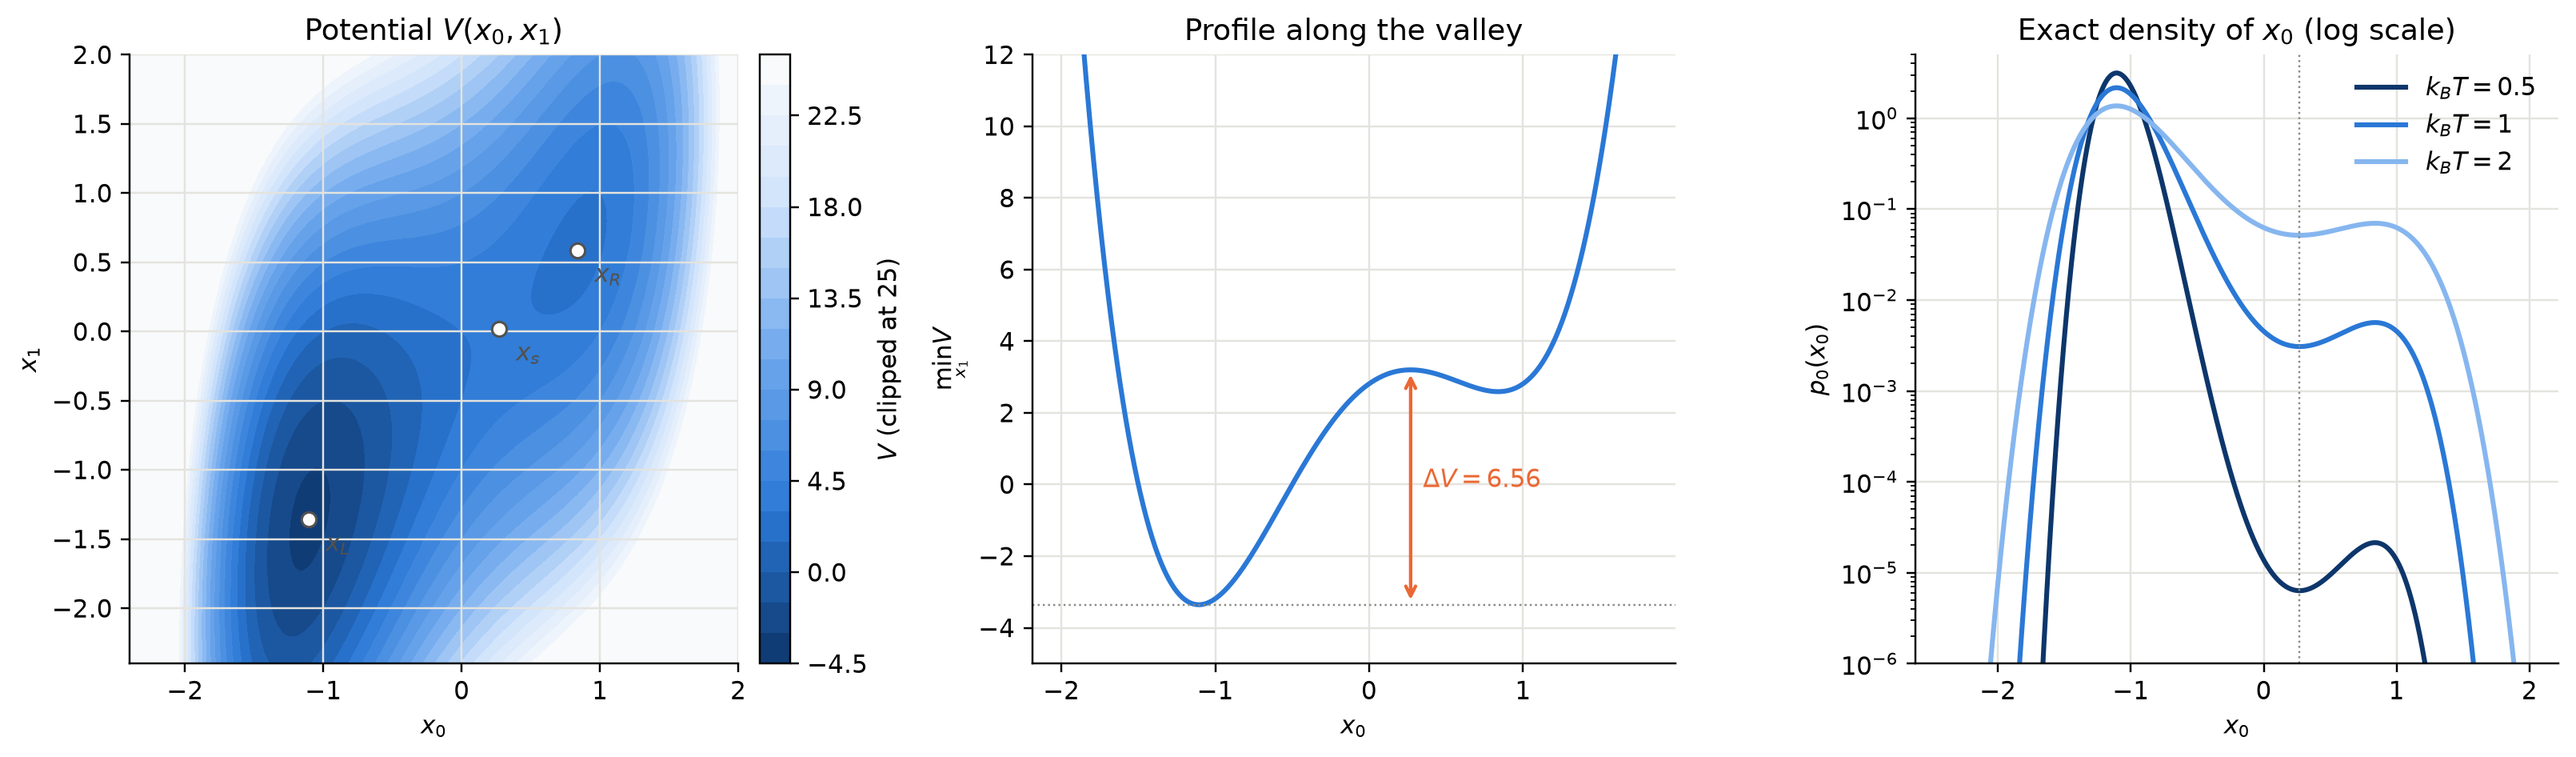

In [6]:
# 4.2 Sanity check of the exact sampler and the landscape
# --- Step 1: critical points and exact reference values ---
print("critical points:", f"x_L = {X_LEFT:.4f}   x_s = {X_SADDLE:.4f}   x_R = {X_RIGHT:.4f}\n")
print(f"{'kT':>5}{'P(right)':>12}{'<x0>':>10}{'<V>':>10}{'barrier/kT':>12}"
      f"{'sample <x0>':>15}{'sample <V>':>13}")
# --- Step 2: averages of the exact sampler vs. the exact values (assert stops the cell if they differ) ---
for kT, r in REF.items():
    x = exact_sample(100_000, kT, seed=5)
    m0, mv = x[:, 0].mean().item(), potential(x).mean().item()
    se0, sev = x[:, 0].std().item() / 100_000**0.5, potential(x).std().item() / 100_000**0.5
    print(f"{kT:5.1f}{r['p_right']:12.3e}{r['mean_x0']:10.4f}{r['mean_v']:10.4f}{r['barrier_kT']:12.2f}"
          f"{m0:15.4f}{mv:13.4f}")
    assert abs(m0 - r["mean_x0"]) < 5 * se0 and abs(mv - r["mean_v"]) < 5 * sev, f"kT = {kT}: sampler off"
print("The exact sampler agrees with the exact values.")

# --- Step 3: potential, profile along the valley, exact density of x_0 ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
cs = landscape(axes[0])
fig.colorbar(cs, ax=axes[0], fraction=0.046, pad=0.03, label="$V$ (clipped at 25)")
crit = np.array([X_LEFT, X_SADDLE, X_RIGHT])
axes[0].plot(crit, crit - D / 2, "o", color="white", mec="#52514e", ms=6)
for xc, lab in zip(crit, ["$x_L$", "$x_s$", "$x_R$"]):
    axes[0].annotate(lab, (xc, xc - D / 2), xytext=(7, -13), textcoords="offset points", color="#52514e")
axes[0].set_title("Potential $V(x_0, x_1)$")

a = torch.linspace(-2.0, 1.8, 800, dtype=F64)
v_valley = potential_x0(a) - EPS * D**2 / 4                       # minimum of V over x_1 at fixed x_0
v_l, v_s, _ = (potential_x0(torch.tensor(crit, dtype=F64)) - EPS * D**2 / 4).tolist()
axes[1].plot(a, v_valley, color=COLORS["target"], lw=2)
axes[1].annotate("", (X_SADDLE, v_s), (X_SADDLE, v_l), arrowprops=dict(arrowstyle="<->", color=COLORS["rf1"], lw=1.4))
axes[1].axhline(v_l, color=COLORS["source"], lw=0.8, ls=":")
axes[1].text(X_SADDLE + 0.08, (v_l + v_s) / 2, rf"$\Delta V = {v_s - v_l:.2f}$", color=COLORS["rf1"])
axes[1].set(ylim=(-5, 12), xlabel="$x_0$", ylabel=r"$\min_{x_1} V$",
            title="Profile along the valley")

g = torch.linspace(-2.4, 2.0, 2000, dtype=F64)
for kT in TEMPS:
    axes[2].plot(g, density_x0(kT, g), color=TEMP_COLORS[kT], lw=2, label=f"$k_BT = {kT:g}$")
axes[2].axvline(X_SADDLE, color=COLORS["source"], lw=0.8, ls=":")
axes[2].set(yscale="log", ylim=(1e-6, 5), xlabel="$x_0$", ylabel="$p_0(x_0)$",
            title="Exact density of $x_0$ (log scale)")
axes[2].legend(loc="upper right")
fig.tight_layout()
save_figure(fig, "system")
plt.show()

> **Observations.**
> - The exact sampler reproduces $\langle x_0 \rangle$ and $\langle V \rangle$ at all three temperatures, so it can serve as the reference for everything that follows.
> - The two minima lie on the valley floor $x_1 = x_0 - d/2$. Seen from the deep left well, the barrier is $\Delta V \approx 6.56$, i.e. $13.1,\ 6.6,\ 3.3$ in units of $k_BT$ at $k_BT = 0.5,\ 1,\ 2$.
> - The right well carries only $P(\text{right}) \approx 1.1\cdot10^{-5},\ 4.0\cdot10^{-3},\ 6.0\cdot10^{-2}$ of the probability. This rare state is the most sensitive test of both the Monte Carlo sampler and the generative models.

## 5. Metropolis Monte Carlo

**In this section:** the sampler and its error analysis (5.1), the training sets at three temperatures (5.2).

### 5.1 Implementation

**In this step**

1. Write the Metropolis algorithm of Section 1.4 for many independent chains (walkers) at once.
2. Write the error analysis of Section 1.5: autocorrelation, $\tau_{\rm int}$ (with Sokal's automatic window: sum $\rho(k)$ up to the first $W \ge 6\,\tau_{\rm int}(W)$) and block standard errors.
3. Write the recipe for one training set: 250 walkers start in the **left minimum** — a simulation would not know about the right well in advance —, step $\sigma = 0.8\sqrt{k_BT}$, burn-in 1000 steps; a pilot run of 5000 steps measures $\tau_{\rm int}$ of $x_0$, the production run is thinned by $\lceil 2\tau_{\rm int} \rceil$ and gives $100\,000$ configurations.

In [7]:
# 5.1 Metropolis Monte Carlo and its error analysis
# --- Step 1: the Metropolis algorithm for W walkers at once ---
@torch.no_grad()
def metropolis(x: torch.Tensor, n_steps: int, step: float, kT: float, seed: int):
    '''Random-walk Metropolis with Gaussian proposals x' = x + step * xi.

    x: (W, 2) starting points of W walkers.
    Returns the trajectory (n_steps, W, 2) as float32 and the mean acceptance rate.
    '''
    g = torch.Generator().manual_seed(seed)
    x = x.to(F64).clone()
    v = potential(x)
    n_acc = torch.zeros(len(x), dtype=F64)
    traj = torch.empty(n_steps, *x.shape, dtype=torch.float32)
    for k in range(n_steps):
        trial = x + step * torch.randn(x.shape, generator=g, dtype=F64)            # 1. propose
        v_trial = potential(trial)                                                  # 2. energy change
        # 3. accept with probability min(1, exp(-dV / kT)); comparing log(u) avoids overflow
        accept = torch.log(torch.rand(len(x), generator=g, dtype=F64)) < -(v_trial - v) / kT
        x = torch.where(accept[:, None], trial, x)
        v = torch.where(accept, v_trial, v)
        n_acc += accept
        traj[k] = x                                                                 # 4. store, also if rejected
    return traj, (n_acc / n_steps).mean().item()


# --- Step 2: autocorrelation, integrated autocorrelation time, block errors ---
def autocorrelation(f: torch.Tensor, max_lag: int) -> torch.Tensor:
    '''Normalised autocorrelation rho(k), k < max_lag, of f (N, W), averaged over walkers (FFT).'''
    f = f.to(F64)
    f = f - f.mean()
    n = f.shape[0]
    spec = torch.fft.rfft(f, n=2 * n, dim=0)
    acov = torch.fft.irfft(spec * spec.conj(), n=2 * n, dim=0)[:max_lag].mean(1)
    acov = acov / torch.arange(n, n - max_lag, -1, dtype=F64)
    return acov / acov[0]


def tau_int(rho: torch.Tensor, c: float = 6.0) -> float:
    '''Integrated autocorrelation time with Sokal's window: the first W with W >= c tau(W).'''
    tau = 0.5 + rho[1:].cumsum(0)
    ok = torch.arange(1, len(rho)) >= c * tau
    return tau[int(torch.nonzero(ok)[0]) if ok.any() else -1].item()


def block_error(f: torch.Tensor, block: int = 1000) -> float:
    '''Standard error of the mean of f (N, W) from non-overlapping blocks within each walker.'''
    nb = f.shape[0] // block
    means = f[: nb * block].to(F64).reshape(nb, block, -1).mean(1).flatten()
    return (means.std() / math.sqrt(len(means))).item()


# --- Step 3: one training set ---
@dataclass
class MCRun:
    data: torch.Tensor          # (n, 2) decorrelated training configurations
    step: float
    acceptance: float
    tau_x0: float
    thin: int
    crossings: int              # left -> right barrier crossings summed over walkers
    n_states: int
    estimates: dict             # name -> (value, standard error) from the full chains
    trace_x0: torch.Tensor      # (N, 4) x_0 of the first walkers, for plotting


def sample_dataset(kT: float, n: int = CFG.n_train, walkers: int = CFG.mc_walkers,
                   burn: int = CFG.mc_burn_in, step_at_kT1: float = CFG.mc_step_at_kT1,
                   seed: int = 0, cache: Path | None = None) -> MCRun:
    '''Training set for one temperature (walkers start in the left minimum; thinning by 2 tau_int).'''
    if cache is not None and cache.exists():
        return MCRun(**torch.load(cache))
    step = step_at_kT1 * math.sqrt(kT)                                              # sigma = 0.8 sqrt(kT)
    start = torch.tensor([[X_LEFT, X_LEFT - D / 2]], dtype=F64).expand(walkers, 2)  # left minimum
    pilot, _ = metropolis(start, 5000, step, kT, seed)                              # pilot run -> tau_int
    tau = tau_int(autocorrelation(pilot[burn:, :, 0], 2000))
    thin = max(1, math.ceil(2 * tau))
    traj, acc = metropolis(start, burn + thin * math.ceil(n / walkers), step, kT, seed + 1)
    chain = traj[burn:]                                                             # drop the burn-in
    data = chain[::thin].reshape(-1, 2)                                             # every thin-th state
    data = data[torch.randperm(len(data), generator=torch.Generator().manual_seed(seed))][:n]
    x0 = chain[..., 0].to(F64)
    right = (x0 > X_SADDLE).to(F64)
    v = potential(chain.to(F64))
    run = MCRun(data=data, step=step, acceptance=acc, tau_x0=tau, thin=thin,
                crossings=int((right[1:] - right[:-1] > 0).sum()), n_states=x0.numel(),
                estimates={"p_right": (right.mean().item(), block_error(right)),
                           "mean_x0": (x0.mean().item(), block_error(x0)),
                           "mean_v": (v.mean().item(), block_error(v))},
                trace_x0=chain[:, :4, 0].clone())
    if cache is not None:
        torch.save(run.__dict__, cache)
    return run

### 5.2 Training sets at $k_BT = 0.5,\ 1,\ 2$

**In this step**

1. Run the recipe of 5.1 for each temperature (or load the stored set from `data/`).
2. Compare the chain averages (with block standard errors) with the exact values. The column $z = (\text{MC} - \text{exact}) / \text{s.e.}$ measures the deviation in standard errors: $|z| \lesssim 2$ means agreement.
3. Plot the $x_0$-histogram of each training set against the exact density.

training sets ready in 0 s

  kT  sigma  acc.   tau  thin     states  L->R    quantity         MC      s.e.      exact     z
 0.5   0.57  0.16   5.8    12   1.20e+06     3     p_right    0.00003   0.00003    0.00001   0.5
                                                   mean_x0   -1.08606   0.00045   -1.08609   0.1
                                                    mean_v   -2.84460   0.00206   -2.84645   0.9
 1.0   0.80  0.17   8.7    18   1.80e+06   845     p_right    0.00409   0.00026    0.00396   0.5
                                                   mean_x0   -1.05110   0.00078   -1.05147   0.5
                                                    mean_v   -2.27829   0.00389   -2.28119   0.7
 2.0   1.13  0.19  10.9    22   2.20e+06 19741     p_right    0.05986   0.00071    0.05978   0.1
                                                   mean_x0   -0.87924   0.00174   -0.88024   0.6
                                                    mean_v   -0.83390   0.00803   -0.84087   0.9


saved: figures/metropolis.png (+ .pdf)


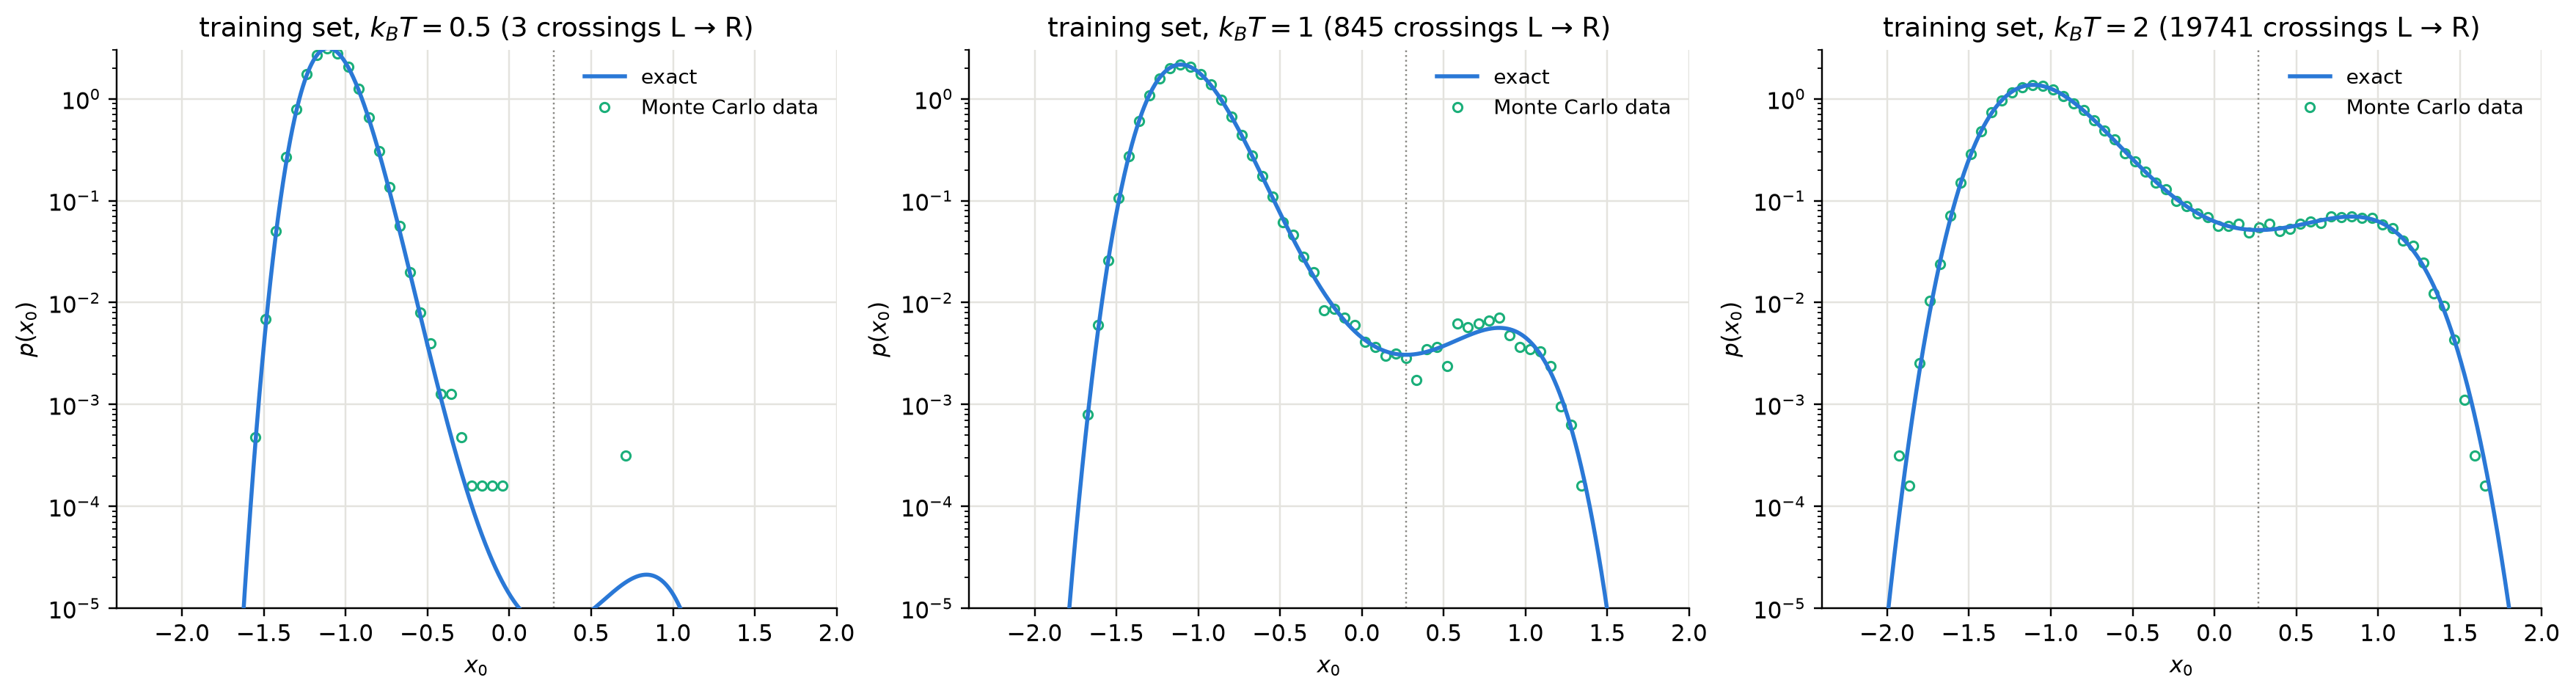

In [8]:
# 5.2 Training sets: run (or load) Metropolis at the three temperatures
# --- Step 1: one Monte Carlo run per temperature ---
start = time.perf_counter()
MC = {kT: sample_dataset(kT, seed=int(100 * kT), cache=DATA_DIR / f"mc_kT{kT}.pt") for kT in TEMPS}
print(f"training sets ready in {time.perf_counter() - start:.0f} s\n")

# --- Step 2: chain averages vs. exact values ---
print(f"{'kT':>4}{'sigma':>7}{'acc.':>6}{'tau':>6}{'thin':>6}{'states':>11}"
      f"{'L->R':>6}   {'quantity':>9}{'MC':>11}{'s.e.':>10}"
      f"{'exact':>11}{'z':>6}")
for kT, run in MC.items():
    for j, q in enumerate(("p_right", "mean_x0", "mean_v")):
        val, se = run.estimates[q]
        head = (f"{kT:4.1f}{run.step:7.2f}{run.acceptance:6.2f}{run.tau_x0:6.1f}{run.thin:6d}{run.n_states:11.2e}"
                f"{run.crossings:6d}" if j == 0 else " " * 46)
        print(f"{head}   {q:>9}{val:11.5f}{se:10.5f}{REF[kT][q]:11.5f}{(val - REF[kT][q]) / se:6.1f}")

# --- Step 3: histograms of x_0 of the training sets ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, kT in zip(axes, TEMPS):
    x0_profile(ax, {"Monte Carlo data": (MC[kT].data, COLORS["data"])}, kT)
    ax.set_title(f"training set, $k_BT = {kT:g}$ ({MC[kT].crossings} crossings L → R)")
    ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
save_figure(fig, "metropolis")
plt.show()

> **Observations.**
> - The column L->R counts the barrier crossings: $19\,741$ at **$k_BT = 2$**, $845$ at **$k_BT = 1$** and only **3** in $1.2\cdot10^6$ states at **$k_BT = 0.5$** (barrier $13\,k_BT$).
> - At all three temperatures the chain averages agree with the exact values ($|z| < 1$). At $k_BT = 1$ and $2$ this is a real success: the error bars are small.
> - At $k_BT = 0.5$ the agreement is empty: the right-well weight is $2.6\cdot10^{-5} \pm 2.8\cdot10^{-5}$ (a $100\,\%$ error), and the training set contains just **two** configurations in the right well. The flat row of markers at $p \approx 1.6\cdot10^{-4}$ in the left panel is not a feature of the data: these are single points, $1/(n\,\Delta x)$, the smallest density a histogram of $10^5$ points can show.
> - Whatever a flow learns about the right well at $k_BT = 0.5$, it learns from two points.

## 6. Velocity network

**In this step**

1. Define the network $v_\theta(t, x)$: the point $x \in \mathbb R^2$ and Fourier features of $t$ are lifted to width $256$, passed through three residual blocks and projected back to $\mathbb R^2$.
2. Print the number of trainable parameters ($399\,106$).

**Design choices.**

- **Fourier features of time** $\sin(\pi 2^{k-1} t),\ \cos(\pi 2^{k-1} t)$, $k = 1, \dots, 6$: the field changes quickly in $t$ near $t = 1$, where the paths decide which well they go to (Section 11.3); these features let the network follow fast changes in $t$.
- **Residual blocks** $h \leftarrow h + \mathrm{MLP}(h)$: each block only adds a correction, which makes a deeper network easy to train.
- **SiLU activation** $z/(1 + e^{-z})$ is smooth, so the velocity field is smooth: the ODE has unique, non-crossing paths and RK4 stays accurate.
- **Linear last layer:** a velocity can be any vector in $\mathbb R^2$.

In [9]:
# 6. Velocity network v_theta(t, x)
# --- Step 1: x and Fourier features of t -> width 256 -> 3 residual SiLU blocks -> velocity in R^2 ---
class VelocityField(nn.Module):
    '''v(t, x): Fourier features of t, concatenated with x, followed by residual SiLU blocks.'''

    def __init__(self, width: int = CFG.hidden_dim, blocks: int = CFG.n_blocks, n_freq: int = CFG.n_freq):
        super().__init__()
        self.register_buffer("freq", math.pi * 2.0 ** torch.arange(n_freq) / 2)   # pi 2^(k-1), k = 1..6
        self.lift = nn.Linear(2 + 2 * n_freq, width)
        self.blocks = nn.ModuleList(
            nn.Sequential(nn.SiLU(), nn.Linear(width, width), nn.SiLU(), nn.Linear(width, width))
            for _ in range(blocks)
        )
        self.head = nn.Sequential(nn.SiLU(), nn.Linear(width, 2))                   # linear output

    def forward(self, t, x: torch.Tensor) -> torch.Tensor:
        '''t: scalar, (B,) or (B, 1); x: (B, 2). Returns the velocity, shape (B, 2).'''
        t = torch.as_tensor(t, dtype=x.dtype, device=x.device).reshape(-1, 1).expand(len(x), 1)
        h = self.lift(torch.cat([x, torch.sin(t * self.freq), torch.cos(t * self.freq)], dim=1))
        for block in self.blocks:
            h = h + block(h)                                                        # residual connection
        return self.head(h)


# --- Step 2: number of trainable parameters ---
print("Trainable parameters:", f"{sum(p.numel() for p in VelocityField().parameters()):,}")

Trainable parameters: 399,106


## 7. Rectified Flow objective and training loop

**In this step:** write the function `train_rf`, used for both 1-RF and reflow. Every iteration (numbered as in the code):

1. draw a batch of $1024$ data points $x_1$ and, for 1-RF, **fresh** noise $x_0$ — for reflow the **fixed** partner $x_0$ of each $x_1$;
2. draw a random time $t \sim \mathcal U[0, 1]$ for every pair and take the point $x_t = t\,x_1 + (1 - t)\,x_0$;
3. compare the prediction $v_\theta(t, x_t)$ with the line's velocity $x_1 - x_0$ (squared error, batch average) — the loss of Section 2.2;
4. update the weights with AdamW; the learning rate rises to $10^{-3}$ in the first $5\,\%$ of the steps and then decreases along a cosine curve (one-cycle schedule);
5. update an **exponential moving average** (EMA) of the weights, $\bar\theta \leftarrow 0.999\,\bar\theta + 0.001\,\theta$, and store the loss.

The returned network uses the averaged weights $\bar\theta$: they fluctuate less than the last weights and give a smoother field. Weights and loss history are saved in `checkpoints/`; if the file exists it is loaded instead of training.

In [10]:
# 7. Rectified Flow training loop (1-RF with fresh noise, or reflow with fixed pairs)
def train_rf(x1: torch.Tensor, x0: torch.Tensor | None = None, *, cache: Path,
             iters: int = CFG.n_iters, batch: int = CFG.batch_size, lr: float = CFG.lr,
             ema: float = CFG.ema, init: nn.Module | None = None, seed: int = 0,
             device="cpu") -> tuple[nn.Module, dict]:
    '''Fit v(t, x) to X1 - X0 along X_t = t X1 + (1 - t) X0; return the EMA network and a log.

    x0 = None: independent pairs, X0 drawn fresh from N(0, I) at every step (1-RF).
    x0 given:  fixed coupled pairs (x0[i], x1[i]) produced by a previous flow (reflow).
    '''
    model = VelocityField().to(device)
    if cache.exists():                                                      # trained before: load
        ckpt = torch.load(cache, map_location="cpu")
        model.load_state_dict(ckpt["state"])
        return model.eval(), ckpt["log"]
    torch.manual_seed(seed)
    if init is not None:                                                    # reflow starts from 1-RF
        model.load_state_dict(init.state_dict())
    avg = deepcopy(model).requires_grad_(False)                             # EMA copy of the weights
    g = torch.Generator(device=device).manual_seed(seed)
    x1 = x1.to(device, torch.float32)
    x0 = None if x0 is None else x0.to(device, torch.float32)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=iters, pct_start=0.05)
    losses, start = torch.zeros(iters, device=device), time.time()
    p_avg, p_model = list(avg.parameters()), list(model.parameters())
    for k in range(iters):
        i = torch.randint(len(x1), (batch,), generator=g, device=device)
        b1 = x1[i]                                                          # 1. data points ...
        b0 = torch.randn(batch, 2, generator=g, device=device) if x0 is None else x0[i]   # ... and their noise
        t = torch.rand(batch, 1, generator=g, device=device)                # 2. one random time per pair
        loss = ((model(t, t * b1 + (1 - t) * b0) - (b1 - b0)) ** 2).sum(1).mean()       # 3. loss of Sec. 2.2
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()                                                          # 4. AdamW update ...
        sched.step()                                                        #    ... and learning-rate schedule
        with torch.no_grad():
            torch._foreach_lerp_(p_avg, p_model, 1 - ema)                   # 5. EMA of the weights
            losses[k] = loss.detach()                                       #    and the loss
    log = {"loss": losses.reshape(-1, 100).mean(1).cpu(),                   # mean of every 100 iterations
           "seconds": time.time() - start, "n_data": len(x1)}
    cache.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state": avg.state_dict(), "log": log}, cache)
    return avg.eval(), log

## 8. RK4 ODE solver

**In this step:** write the time grid and the function `rk4`, which moves all points from $t = 0$ to $t = 1$ in $N$ steps.

RK4 evaluates the field four times per step $h_n = t_{n+1} - t_n$ — at the start, twice at the midpoint and at the end — and moves along their weighted average:

$$k_1 = v(t_n, z_n), \quad k_2 = v\big(t_n + \tfrac{h_n}2,\ z_n + \tfrac{h_n}2 k_1\big), \quad k_3 = v\big(t_n + \tfrac{h_n}2,\ z_n + \tfrac{h_n}2 k_2\big), \quad k_4 = v\big(t_{n+1},\ z_n + h_n k_3\big),$$

$$z_{n+1} = z_n + \tfrac{h_n}6\,(k_1 + 2k_2 + 2k_3 + k_4).$$

- **Error** $\propto h^4$; **cost** $4N$ network evaluations (NFE).
- **Time grid.** By default the nodes are uniform, $t_n = n/N$. Section 11.5 compares three other placements: *late* $t_n = 1 - (1 - n/N)^2$ (dense near the data), *early* $t_n = (n/N)^2$ (dense near the noise) and *cosine* $t_n = \tfrac12(1 - \cos\frac{\pi n}{N})$ (dense at both ends).

In [11]:
# 8. Time grids and the RK4 solver
def time_grid(n_steps: int, kind: str = "uniform") -> torch.Tensor:
    '''Integration nodes 0 = t_0 < ... < t_N = 1 (uniform, late, early or cosine; see above).'''
    s = torch.linspace(0.0, 1.0, n_steps + 1)
    return {
        "uniform": s,
        "late": 1 - (1 - s) ** 2,
        "early": s**2,
        "cosine": (1 - torch.cos(math.pi * s)) / 2,
    }[kind]


@torch.no_grad()
def rk4(v, z: torch.Tensor, n_steps: int = 100, grid: str = "uniform", keep_path: bool = False):
    '''Classical 4th-order Runge-Kutta for dx/dt = v(t, x) from t = 0 to t = 1.

    Returns x(1), or the whole path (N + 1, n, 2) when keep_path is True.
    '''
    ts = time_grid(n_steps, grid).tolist()
    x, path = z.clone(), [z.clone()] if keep_path else None
    for t, t_next in zip(ts[:-1], ts[1:]):
        h = t_next - t
        k1 = v(t, x)
        k2 = v(t + h / 2, x + h / 2 * k1)
        k3 = v(t + h / 2, x + h / 2 * k2)
        k4 = v(t_next, x + h * k3)
        x = x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        if keep_path:
            path.append(x.clone())
    return torch.stack(path) if keep_path else x

## 9. Reflow pairs and straightness

**In this step**

1. `reflow_pairs`: draw $100\,000$ fresh noise points $z$ and move each of them with the trained flow (RK4, $100$ steps); the pairs $(z,\ \Phi(z))$ are the training data of the next flow (Section 2.5).
2. `straightness`: compute $S$ of Section 2.6 along RK4 paths. The velocity of the path is the field itself, $\dot Z_t = v(t, Z_t)$, so $S$ is the time average of $\|(Z_1 - Z_0) - v(t, Z_t)\|^2$, divided by $\mathbb E\|Z_1 - Z_0\|^2$.

In [12]:
# 9. Reflow pairs and straightness
# --- Step 1: pairs (noise, its own generated sample) for the next flow ---
@torch.no_grad()
def reflow_pairs(v, n: int, seed: int, device, n_steps: int = CFG.reflow_steps):
    '''Couple fresh noise Z with the endpoint of its own trajectory: (Z, ODE_v(Z)).'''
    z = torch.randn(n, 2, generator=torch.Generator().manual_seed(seed)).to(device)
    return z, rk4(v, z, n_steps)


# --- Step 2: straightness S along the RK4 paths ---
@torch.no_grad()
def straightness(v, z: torch.Tensor, n_steps: int = 100) -> float:
    '''S = E int_0^1 || (Z_1 - Z_0) - v(t, Z_t) ||^2 dt / E || Z_1 - Z_0 ||^2 (zero for straight paths).'''
    path = rk4(v, z, n_steps, keep_path=True)
    chord = path[-1] - path[0]
    ts = time_grid(n_steps).tolist()
    dev = torch.stack([((chord - v(t, x)) ** 2).sum(1).mean() for t, x in zip(ts, path)])
    return (torch.trapezoid(dev, torch.tensor(ts, device=dev.device)) / (chord**2).sum(1).mean()).item()

## 10. Training

**In this step**

1. Write two helpers: `fit` trains a network with `train_rf` (or loads it from `checkpoints/`), `rectify` builds the reflow pairs of a trained flow and trains the next one, starting from its weights.
2. Train **eight** networks:
   - 1-RF and 2-RF at each temperature $k_BT = 0.5,\ 1,\ 2$, on the $100\,000$ Monte Carlo configurations of Section 5.2;
   - 1-RF at $k_BT = 1$ on only the first $1\,000$ and $10\,000$ configurations (Section 11.7).
3. Print the training time and the final loss of each network.

Every network uses the same settings ($20\,000$ iterations, batch $1024$); training takes about $1.5$ minutes per network on a GPU.

In [13]:
# 10. Train (or load) all networks
# --- Step 1: helpers ---
def fit(name: str, x1: torch.Tensor, x0: torch.Tensor | None = None, **kw):
    '''Train a network with train_rf, or load it from checkpoints/<name>.pt.'''
    model, log = train_rf(x1, x0, cache=CKPT_DIR / f"{name}.pt", device=DEV, **kw)
    # --- Step 3: training time and final loss ---
    print(f"  {name:22s}  n = {log['n_data']:>7,d}  {log['seconds']:5.0f} s  "
          + "final loss" + f" {log['loss'][-20:].mean():.4f}")
    return model, log


def rectify(name: str, prev: nn.Module, seed: int):
    '''Reflow: pair fresh noise with the samples of `prev` and train the next flow from its weights.'''
    if (CKPT_DIR / f"{name}.pt").exists():
        return fit(name, torch.empty(0, 2))
    z, x1 = reflow_pairs(prev, CFG.n_reflow, seed=seed, device=DEV)
    return fit(name, x1, z, init=prev, seed=seed)


# --- Step 2: 1-RF and 2-RF at every temperature, 1-RF on smaller training sets ---
MODELS, LOGS = {}, {}
REFLOW_SEED = {0.5: 21, 1.0: 21, 2.0: 81}
print("training (stored weights are loaded from checkpoints/):")
for kT in TEMPS:
    MODELS[kT, 1], LOGS[kT, 1] = fit(f"rf1_kT{kT}", MC[kT].data)                       # 1-RF
    MODELS[kT, 2], LOGS[kT, 2] = rectify(f"rf2_kT{kT}", MODELS[kT, 1], REFLOW_SEED[kT])  # 2-RF
for n in CFG.train_sizes[:-1]:
    MODELS["n", n], LOGS["n", n] = fit(f"rf1_kT1.0_n{n}", MC[1.0].data[:n])              # 1-RF, fewer data
MODELS["n", CFG.train_sizes[-1]], LOGS["n", CFG.train_sizes[-1]] = MODELS[1.0, 1], LOGS[1.0, 1]

training (stored weights are loaded from checkpoints/):


  rf1_kT0.5               n = 100,000     84 s  final loss 0.6900
  rf2_kT0.5               n = 100,000     83 s  final loss 0.0000
  rf1_kT1.0               n = 100,000     83 s  final loss 1.0373


  rf2_kT1.0               n = 100,000     82 s  final loss 0.0000
  rf1_kT2.0               n = 100,000     83 s  final loss 1.8119
  rf2_kT2.0               n = 100,000     81 s  final loss 0.0000
  rf1_kT1.0_n1000         n =   1,000     79 s  final loss 1.0430
  rf1_kT1.0_n10000        n =  10,000     81 s  final loss 1.0325


## 11. Results

**In this section:** the results, all computed from the trained networks. Each subsection ends with **Observations** — what the figure and the numbers show.

### 11.0 Evaluation setup

**In this step**

1. Write the exact velocity field $v^*$ of 1-RF (formula below), the reference for the field error (11.3).
2. Write the four sample metrics and the field error.
3. Draw the exact reference samples and one shared noise cloud $Z_0$; write the result cache.
4. Generate $200\,000$ samples with every model (RK4, $N = 50$).

**Exact field.** Let $s = 1 - t$ and $\tau^2 = k_BT / 2\varepsilon$. Given the $x_0$-coordinate $a$ of the data point, the point $X_t = t X_1 + s X_0$ is Gaussian:

$$y_0 \mid a \sim \mathcal N(t\,a,\ s^2), \qquad y_1 \mid a \sim \mathcal N\big(t\,(a - \tfrac d2),\ s^2 + t^2\tau^2\big).$$

With the posterior weight $w(a) \propto p_0(a)\,\mathcal N(y_0;\,t a,\, s^2)\,\mathcal N\big(y_1;\, t(a - \tfrac d2),\, s^2 + t^2\tau^2\big)$, normalised over $a$,

$$\mathbb E[X_1 \mid X_t = y] = \int w(a)\,\Big(a,\;\; m + \frac{t\tau^2}{s^2 + t^2\tau^2}\,(y_1 - t\,m)\Big)\,da, \qquad m = a - \frac d2, \qquad v^*(t, y) = \frac{\mathbb E[X_1 \mid X_t = y] - y}{s}.$$

The weights $w(a)$ are the probabilities that a particle at $y$ is on its way to the data points with $x_0 = a$. The integral is a weighted sum over a grid of $8001$ values of $a$. It is the exact target of 1-RF; for 2-RF no such formula exists, because its target depends on the learned 1-RF.

**Metrics.** Every comparison is against an exact sample.
- $P(\text{right})$ — the fraction with $x_0 > x_s$, with binomial standard error $\sqrt{p(1 - p)/n}$; the column $z$ is the deviation from the exact value in standard errors of an exact sample of the same size;
- **TV** — total variation distance $\tfrac12 \sum_j |q_j - p_j|$ between the $x_0$-histogram (80 bins) and the exact bin probabilities: the shape along the valley;
- $\langle V \rangle$ — the mean energy: sensitive to the width of the cloud, including across the valley;
- **ED** — the energy distance $2\,\mathbb E\|X - Y\| - \mathbb E\|X - X'\| - \mathbb E\|Y - Y'\|$ (Székely) between $5000$ generated and $5000$ exact points: zero only for identical distributions; the unbiased estimate can be slightly negative;
- **field error** — $\mathbb E\|v_\theta - v^*\|^2 / \mathbb E\|v^*\|^2$ at fixed $t$, on $4000$ points of the true path $t X_1 + (1 - t) X_0$.

The row **exact control** of every table is a second, independent exact sample: its deviations are pure sampling noise and set the scale below which differences mean nothing.

**Shared noise.** One noise cloud $Z_0$ of $200\,000$ points (seed $2024$) is reused for every model and every $N$, so differences between results come from the model or the solver, not from different random numbers. Sweeps (11.2, 11.4, 11.5) use its first $20\,000$ points.

In [14]:
# 11.0 (a) Exact velocity field v*(t, y) of 1-RF (formula above)
A_GRID = torch.linspace(-3.0, 2.5, 8_001, dtype=F64)  # grid over a = x_0-coordinate of the data point


@torch.no_grad()
def exact_velocity(t: float, y: torch.Tensor, kT: float, chunk: int = 2048) -> torch.Tensor:
    '''Exact v*(t, y) = E[X1 - X0 | X_t = y] = (E[X1 | X_t = y] - y) / (1 - t), as a weighted sum over a.'''
    s2, tau2 = (1 - t) ** 2, kT / (2 * EPS)
    dev = y.device
    a = A_GRID.to(dev)
    log_p0 = -potential_x0(a) / kT
    m = a - D / 2                                              # E[X1_1 | a]
    var1 = s2 + t**2 * tau2                                    # Var[y_1 | a]
    out = []
    for yc in y.to(dev, F64).split(chunk):
        y0, y1 = yc[:, :1], yc[:, 1:]
        logw = log_p0 - (y0 - t * a) ** 2 / (2 * s2) - (y1 - t * m) ** 2 / (2 * var1)
        w = torch.softmax(logw, dim=1)                         # posterior weights w(a)
        e10 = (w * a).sum(1, keepdim=True)
        e11 = (w * (m + t * tau2 / var1 * (y1 - t * m))).sum(1, keepdim=True)
        out.append((torch.cat([e10, e11], dim=1) - yc) / (1 - t))
    return torch.cat(out)

In [15]:
# 11.0 (b) Metrics: P(right), TV, <V>, energy distance, field error
EDGES = torch.linspace(-2.2, 1.8, 81, dtype=F64)  # x_0-bins for the total variation distance


def energy_distance(a: torch.Tensor, b: torch.Tensor, n: int = 5000) -> float:
    '''Unbiased estimate of 2 E|X - Y| - E|X - X'| - E|Y - Y'| (Szekely) on n points each.'''
    dev = a.device if a.is_cuda else b.device
    a, b = a[:n].to(dev, torch.float32), b[:n].to(dev, torch.float32)

    def mean_dist(x, y, same):
        d = torch.cdist(x, y)
        return d.sum() / (len(x) * (len(x) - 1)) if same else d.mean()   # same sample: drop the zero diagonal

    return (2 * mean_dist(a, b, False) - mean_dist(a, a, True) - mean_dist(b, b, True)).item()


def score(x: torch.Tensor, kT: float, exact: torch.Tensor) -> dict:
    '''Right-well weight (+ its binomial s.e.), TV over x_0-bins, <V>, energy distance to `exact`.'''
    x64 = x.detach().cpu().to(F64)
    p = (x64[:, 0] > X_SADDLE).to(F64).mean().item()
    q = torch.histogram(x64[:, 0], bins=EDGES).hist / len(x64)
    return {
        "p_right": p,
        "p_se": math.sqrt(p * (1 - p) / len(x64)),
        "n": len(x64),
        "tv": 0.5 * (q - bin_probabilities(kT, EDGES)).abs().sum().item(),
        "mean_v": potential(x64).mean().item(),
        "ed": energy_distance(x, exact),
    }


@torch.no_grad()
def field_error(v, kT: float, exact: torch.Tensor, ts, n: int = 4000, seed: int = 7):
    '''E||v - v*||^2 / E||v*||^2 at each t in ts, on points t X1 + (1 - t) X0 of the true path.'''
    g = torch.Generator().manual_seed(seed)
    dev = next(v.parameters()).device
    x1 = exact[:n].to(dev, torch.float32)
    out = []
    for t in ts:
        y = t * x1 + (1 - t) * torch.randn(n, 2, generator=g).to(dev)
        ve = exact_velocity(t, y, kT).float()
        out.append((((v(t, y) - ve) ** 2).sum(1).mean() / (ve**2).sum(1).mean()).item())
    return out

In [16]:
# 11.0 (c) Reference samples, shared noise, result cache and generated samples
# --- Step 3: exact samples, shared noise Z_0, result cache ---
X_REF = {kT: exact_sample(CFG.n_eval, kT, seed=11 + int(10 * kT)).float().to(DEV) for kT in TEMPS}
X_CTRL = {kT: exact_sample(CFG.n_eval, kT, seed=12 + int(10 * kT)).float().to(DEV) for kT in TEMPS}   # exact control
Z_EVAL = torch.randn(CFG.n_eval, 2, generator=torch.Generator().manual_seed(2024)).to(DEV)            # shared Z_0
Z_SWEEP = Z_EVAL[:CFG.n_sweep]                                                                         # for the sweeps


def cached(name: str, compute):
    '''Compute once and store in results/<name>.pt; load afterwards (CPU tensors or numbers only).'''
    path = RESULTS_DIR / f"{name}.pt"
    if path.exists():
        return torch.load(path, map_location="cpu", weights_only=False)
    out = compute()
    torch.save(out, path)
    return out


def sample(name: str, v, n_steps: int = CFG.rk4_steps) -> torch.Tensor:
    '''Generated sample of CFG.n_eval points from the shared noise Z_0 (stored in results/).'''
    return cached(name, lambda: rk4(v, Z_EVAL, n_steps).cpu()).to(DEV)


def table(rows: dict, kT: float) -> None:
    '''Print the four metrics of every sample in `rows`, with the exact control first.'''
    r = REF[kT]
    print(f"k_BT = {kT:g}:  " + "exact" + f"  P(right) = {r['p_right']:.3e},  <V> = {r['mean_v']:.4f}")
    print(f"{'':32}{'P(right) ± s.e.':>21}{'count':>8}{'rel.':>8}{'z':>7}"
          f"{'TV':>8}{'<V>':>9}{'ED·1e3':>9}")
    rows = {"exact control (noise)": score(X_CTRL[kT], kT, X_REF[kT]), **rows}
    for name, e in rows.items():
        rel = e["p_right"] / r["p_right"] - 1
        z = (e["p_right"] - r["p_right"]) / (r["p_right"] * (1 - r["p_right"]) / e["n"]) ** 0.5
        print(f"{name:32}{e['p_right']:10.3e} ± {e['p_se']:.1e}{round(e['p_right'] * e['n']):8d}{rel:+8.0%}{z:+7.1f}"
              f"{e['tv']:8.4f}{e['mean_v']:9.4f}{1e3 * e['ed']:9.3f}")


# --- Step 4: 200 000 samples per model (RK4, N = 50); 2-RF also with a single step ---
GEN = {}
for kT in TEMPS:
    for k in (1, 2):
        GEN[kT, k] = sample(f"gen_rf{k}_kT{kT}", MODELS[kT, k])
    GEN[kT, "2-RF, 1 step"] = sample(f"gen_rf2_kT{kT}_1step", MODELS[kT, 2], n_steps=1)
for n in CFG.train_sizes[:-1]:
    GEN["n", n] = sample(f"gen_rf1_kT1.0_n{n}", MODELS["n", n])
GEN["n", CFG.train_sizes[-1]] = GEN[1.0, 1]
print(f"{len(GEN)} generated samples of {CFG.n_eval:,} points ready (RK4, N = {CFG.rk4_steps}).")

12 generated samples of 200,000 points ready (RK4, N = 50).


### 11.1 Generated vs. target samples ($k_BT = 1$)

**In this step**

1. Show the exact samples, the Monte Carlo training data and the samples of 1-RF and 2-RF as point clouds.
2. Show their densities as 2D histograms with the same bins and the same colour scale.
3. Compare the distributions of $x_0$ and print the four metrics.

**Shown.** The 2D histograms estimate the density by counting points in small squares (bins) of side $\Delta$, $\hat p(\text{bin}) = \#\{\text{points in the bin}\} / (n\,\Delta^2)$, on a **logarithmic** colour scale — otherwise the right well, which holds $0.4\,\%$ of the mass, would be invisible.

saved: figures/samples_kT1.png (+ .pdf)


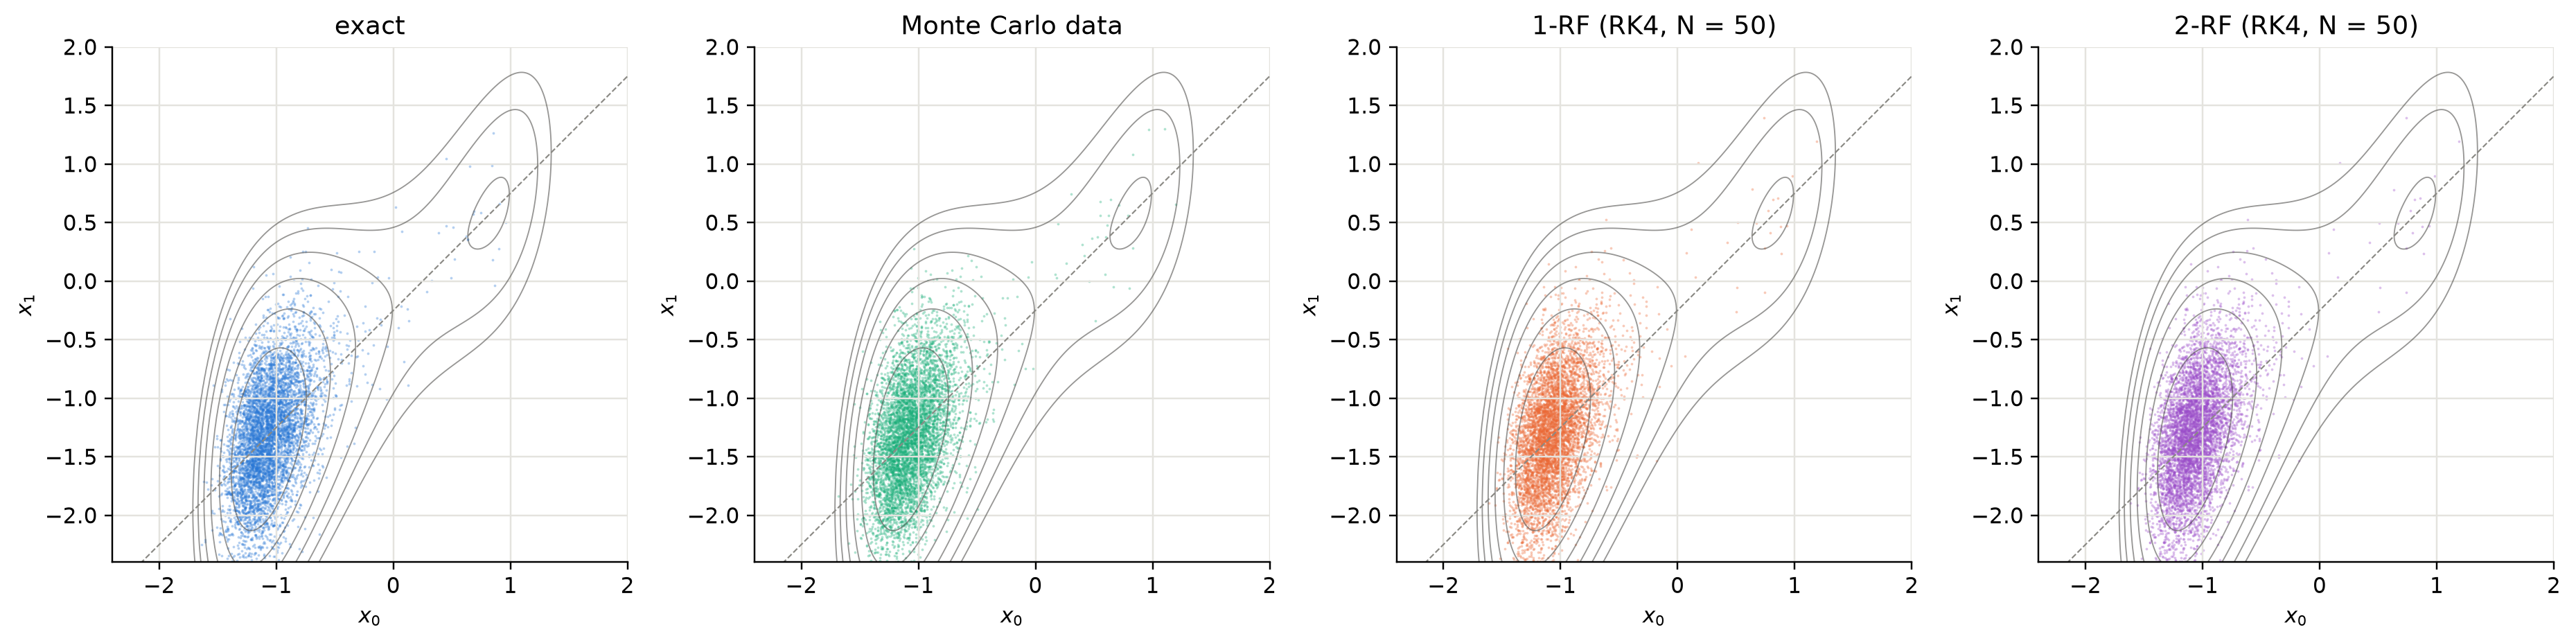

saved: figures/densities_kT1.png (+ .pdf)


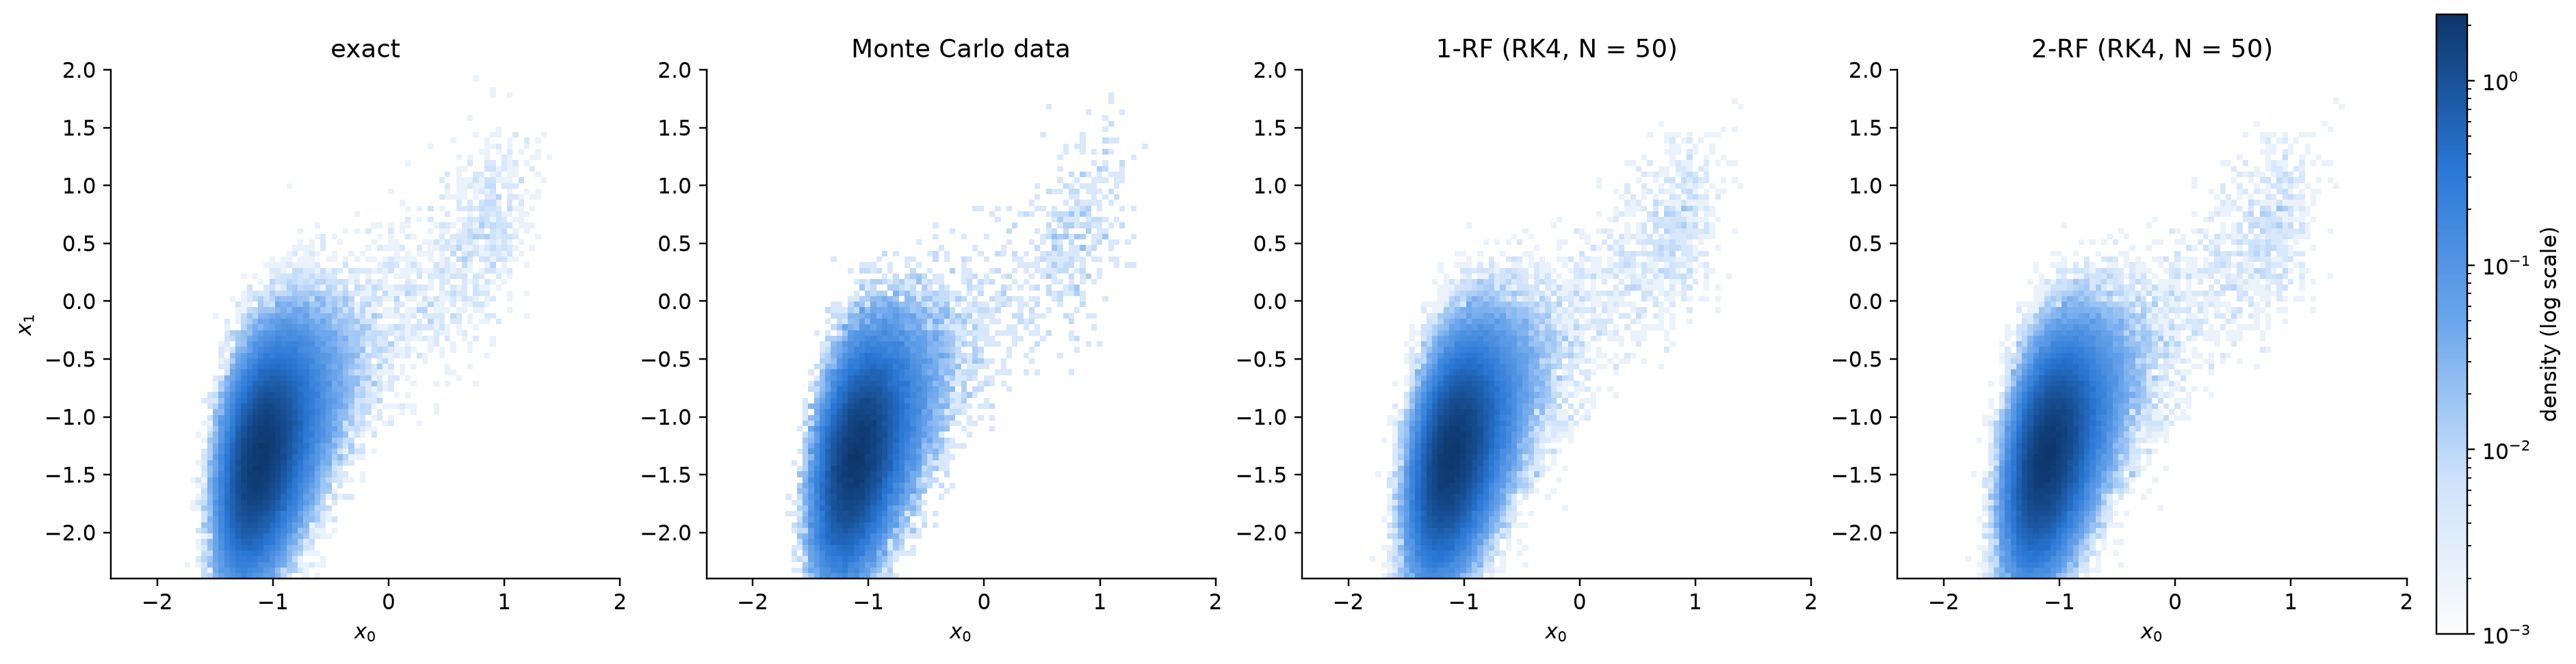

saved: figures/x0_kT1.png (+ .pdf)


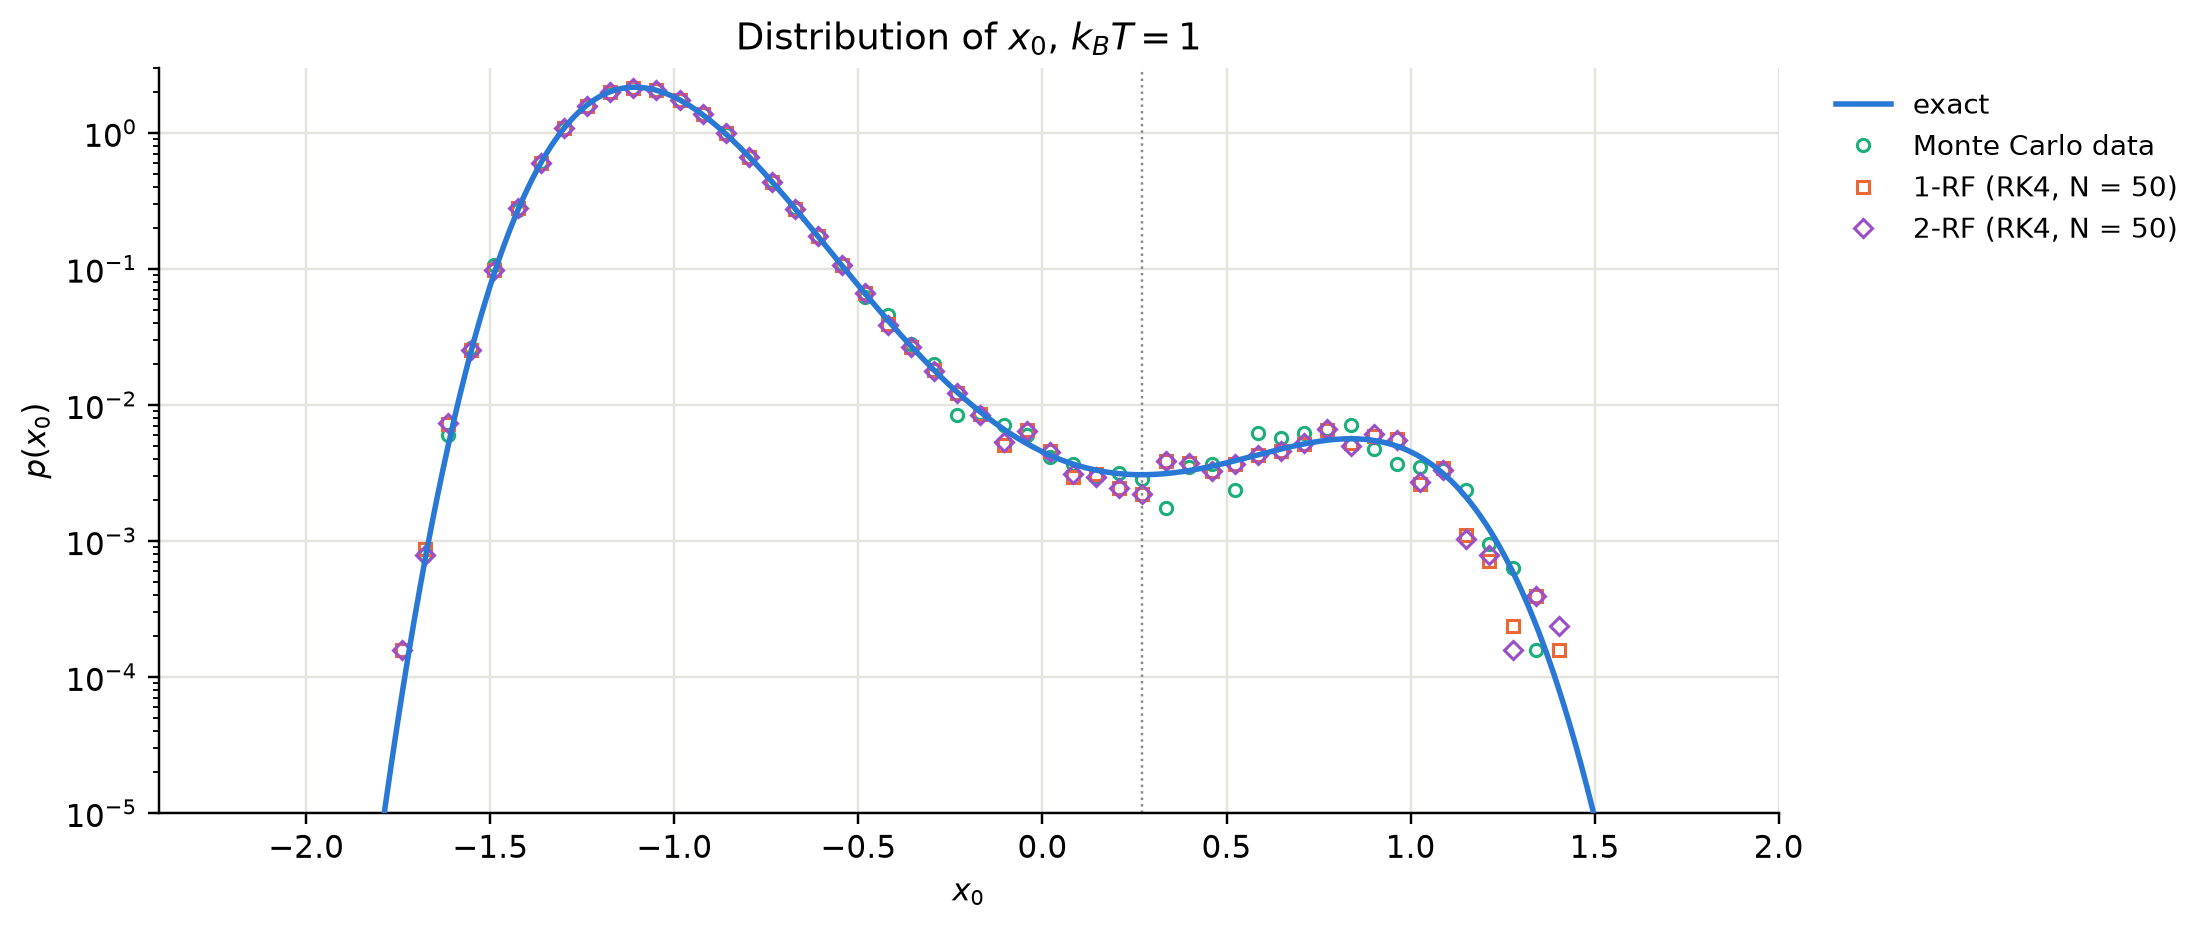

k_BT = 1:  exact  P(right) = 3.957e-03,  <V> = -2.2812
                                      P(right) ± s.e.   count    rel.      z      TV      <V>   ED·1e3
exact control (noise)            4.005e-03 ± 1.4e-04     801     +1%   +0.3  0.0032  -2.2808   -0.057
Monte Carlo data                 4.050e-03 ± 2.0e-04     405     +2%   +0.5  0.0053  -2.2795    0.102
1-RF (RK4, N = 50)               3.890e-03 ± 1.4e-04     778     -2%   -0.5  0.0042  -2.2851    0.116
2-RF (RK4, N = 50)               3.890e-03 ± 1.4e-04     778     -2%   -0.5  0.0042  -2.2851    0.116


In [17]:
# 11.1 Generated vs. target samples at k_B T = 1
SETS = {"exact": (X_REF[1.0], COLORS["target"]),
        "Monte Carlo data": (MC[1.0].data, COLORS["data"]),
        f"1-RF (RK4, N = {CFG.rk4_steps})": (GEN[1.0, 1], COLORS["rf1"]),
        f"2-RF (RK4, N = {CFG.rk4_steps})": (GEN[1.0, 2], COLORS["rf2"])}

# --- Step 1: point clouds ---
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, (name, (x, color)) in zip(axes, SETS.items()):
    cloud(ax, x, color, kT=1.0)
    ax.set_title(name)
fig.tight_layout()
save_figure(fig, "samples_kT1")
plt.show()

# --- Step 2: densities (same bins and logarithmic colour scale) ---
bins = np.linspace(LIM[0], LIM[1], 91)
hists = {name: np.histogram2d(*x.cpu().numpy().T, bins=[bins, bins], density=True)[0] for name, (x, _) in SETS.items()}
vmax = max(h.max() for h in hists.values())
fig, axes = plt.subplots(1, 4, figsize=(17, 4.3), layout="constrained")
for ax, (name, h) in zip(axes, hists.items()):
    im = ax.imshow(np.ma.masked_equal(h.T, 0), origin="lower", extent=(*LIM, *LIM), cmap=DENSITY_CMAP,
                   norm=LogNorm(vmin=1e-3, vmax=vmax), interpolation="nearest")
    ax.set(title=name, xlabel="$x_0$", aspect="equal")
    ax.grid(False)
axes[0].set_ylabel("$x_1$")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="density (log scale)")
save_figure(fig, "densities_kT1")
plt.show()

# --- Step 3: distribution of x_0 and the four metrics ---
fig, ax = plt.subplots(figsize=(9.5, 4.4))
x0_profile(ax, dict(list(SETS.items())[1:]), 1.0)
ax.set_title("Distribution of $x_0$, $k_BT = 1$")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=9)
save_figure(fig, "x0_kT1")
plt.show()
table({"Monte Carlo data": score(MC[1.0].data, 1.0, X_REF[1.0]),
       **{f"{k}-RF (RK4, N = {CFG.rk4_steps})": score(GEN[1.0, k], 1.0, X_REF[1.0]) for k in (1, 2)}}, 1.0)

> **Observations.**
> - 1-RF reproduces the distribution as well as its training data do. It puts $3.89\cdot10^{-3}$ of its samples into the right well against the exact $3.96\cdot10^{-3}$ ($-2\,\%$, $z = -0.5$); TV $= 0.0042$, $\langle V \rangle = -2.285$ against $-2.281$, energy distance $1.2\cdot10^{-4}$. For comparison, the exact control gives TV $= 0.0032$ and $|\mathrm{ED}| \approx 0.6\cdot10^{-4}$, the Monte Carlo data TV $= 0.0053$ and ED $= 1.0\cdot10^{-4}$: every metric is at the level of the sampling noise.
> - The clouds and the densities are visually indistinguishable, including the faint right well and the narrow valley across the diagonal.
> - **2-RF gives the same numbers to all printed digits** — the same $778$ of $200\,000$ points in the right well. Reflow did not change the distribution (Section 2.5, property 1); it reproduces the 1-RF map exactly, including its errors.

### 11.2 Trajectories from $t = 0$ to $t = 1$

**In this step**

1. Compute the straightness $S$ and the transport cost $\mathbb E\|Z_1 - Z_0\|^2$ of 1-RF and 2-RF on $20\,000$ paths.
2. Move 40 noise points with RK4 ($100$ steps) — among them the first 6 that end in the right well — and draw their paths together with the straight segments between start and end point.

**How to read it.** A path is straight exactly when its velocity stays constant, $\dot Z_t = Z_1 - Z_0$. Paths cannot cross, because an ODE has a single velocity at every point and time.

            straightness S        cost E|Z1 - Z0|^2
1-RF              7.68e-02                   3.7383
2-RF              5.16e-08                   3.7382


saved: figures/trajectories.png (+ .pdf)


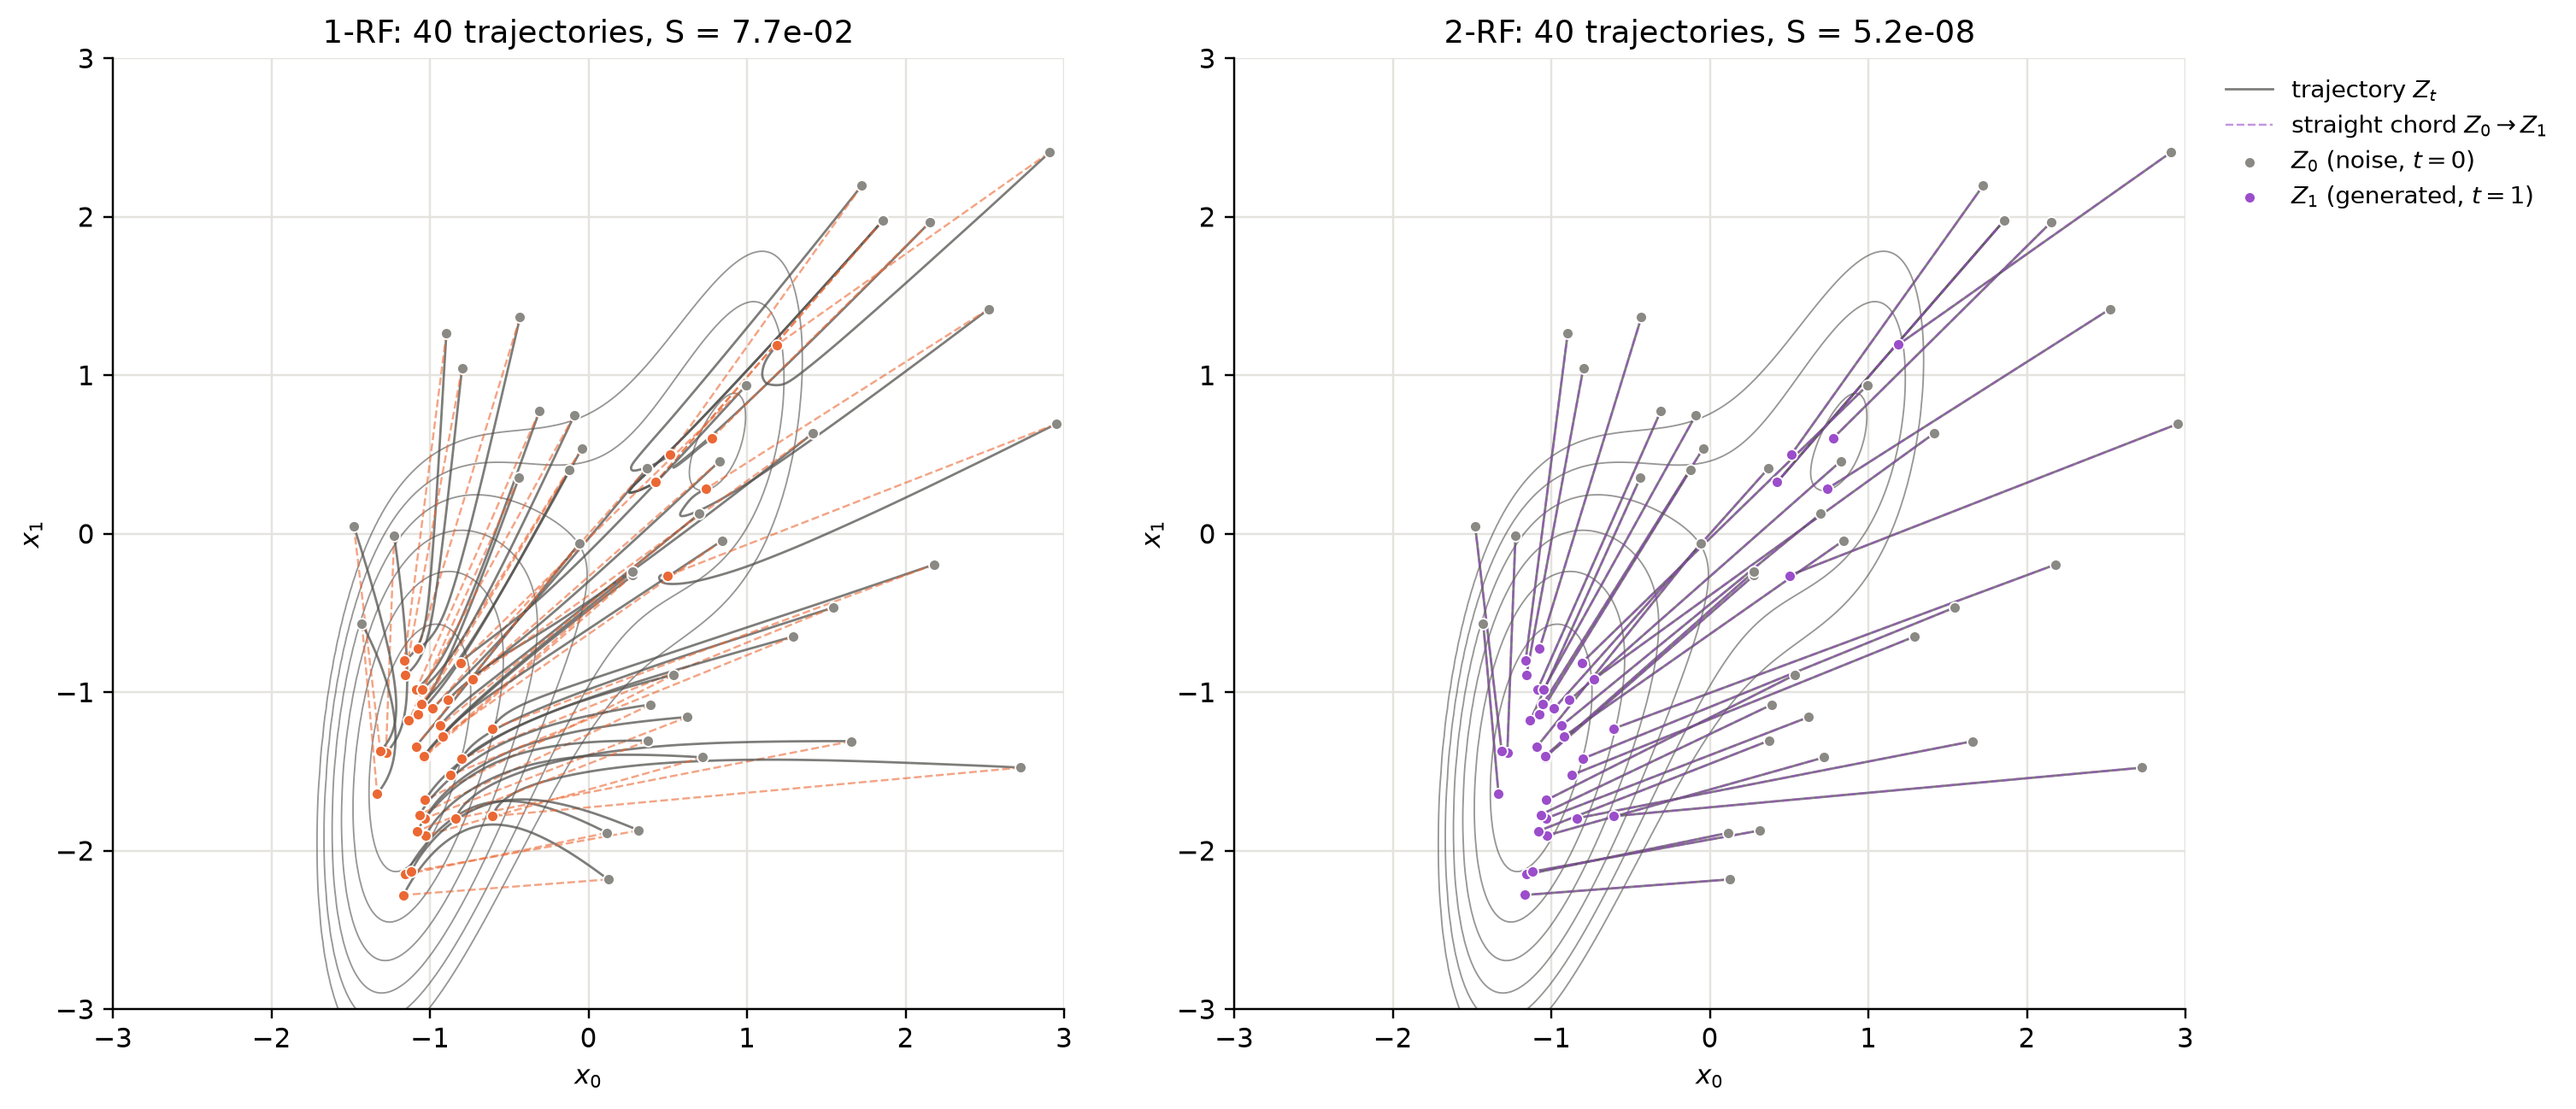

In [18]:
# 11.2 Straightness, transport cost and trajectories (k_B T = 1)
# --- Step 1: straightness S and transport cost of 1-RF and 2-RF ---
STRAIGHT = cached("straightness_kT1.0", lambda: {k: straightness(MODELS[1.0, k], Z_SWEEP) for k in (1, 2)})
COST = cached("cost_kT1.0", lambda: {k: ((rk4(MODELS[1.0, k], Z_SWEEP, CFG.rk4_steps) - Z_SWEEP) ** 2).sum(1).mean().item()
                                     for k in (1, 2)})
print(f"{'':6}{'straightness S':>20}{'cost E|Z1 - Z0|^2':>25}")
for k in (1, 2):
    print(f"{k}-RF  {STRAIGHT[k]:20.2e}{COST[k]:25.4f}")

# --- Step 2: 40 paths, among them 6 that end in the right well ---
pick = torch.cat([torch.nonzero(GEN[1.0, 1][:, 0] > X_SADDLE)[:6, 0], torch.arange(CFG.n_trajectories - 6, device=DEV)])
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, k in zip(axes, (1, 2)):
    paths = rk4(MODELS[1.0, k], Z_EVAL[pick], 100, keep_path=True).cpu().numpy()
    landscape(ax, 1.0, lim=(-3, 3), filled=False)
    for j in range(paths.shape[1]):
        ax.plot(paths[:, j, 0], paths[:, j, 1], color="#52514e", lw=0.9, alpha=0.75,
                label="trajectory $Z_t$" if j == 0 else None)
        ax.plot(paths[[0, -1], j, 0], paths[[0, -1], j, 1], ls="--", lw=0.8, color=COLORS[f"rf{k}"], alpha=0.6,
                label=r"straight chord $Z_0 \to Z_1$" if j == 0 else None)
    ax.scatter(paths[0, :, 0], paths[0, :, 1], s=18, color=COLORS["source"], edgecolors="white", linewidths=0.6,
               zorder=3, label=r"$Z_0$ (noise, $t = 0$)")
    ax.scatter(paths[-1, :, 0], paths[-1, :, 1], s=18, color=COLORS[f"rf{k}"], edgecolors="white", linewidths=0.6,
               zorder=3, label=r"$Z_1$ (generated, $t = 1$)")
    ax.set_title(f"{k}-RF: {CFG.n_trajectories} " + "trajectories" + f", S = {STRAIGHT[k]:.1e}")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=9)
fig.tight_layout()
save_figure(fig, "trajectories")
plt.show()

> **Observations.**
> - **1-RF paths bend.** They first run towards the bulk of the data and turn late, when it becomes clear which well they go to; the six paths that end in the right well show this best. Straightness $S = 7.7\cdot10^{-2}$.
> - **2-RF paths are straight segments** and lie exactly on their dashed chords: $S = 5\cdot10^{-8}$, a reduction by six orders of magnitude after one reflow.
> - The transport cost stays at $3.738$: 1-RF is already close to the cheapest transport between these two distributions, and reflow only guarantees that the cost cannot grow (Section 2.5, property 2).
> - No two paths cross in either panel.

### 11.3 Learned velocity field

**In this step**

1. Draw the exact field $v^*$ and the fields of 1-RF and 2-RF at $t = 0.1,\ 0.4,\ 0.7,\ 0.9$: arrows for the direction, colour for the speed.
2. Compute the field error of 1-RF and 2-RF against $v^*$ at 12 times $t \in [0.02, 0.95]$ and plot it.

**Shown:** the field on a $26 \times 26$ grid, only where the density of $X_t$ is not negligible (at least 8 of $200\,000$ points of $X_t$ in the cell). Arrows show only the direction $v / \|v\|$, colour shows the speed $\|v\|$. Grey points are samples of $X_t = t\,X_1 + (1 - t)\,X_0$, i.e. where the mass is at time $t$.

saved: figures/velocity_field.png (+ .pdf)


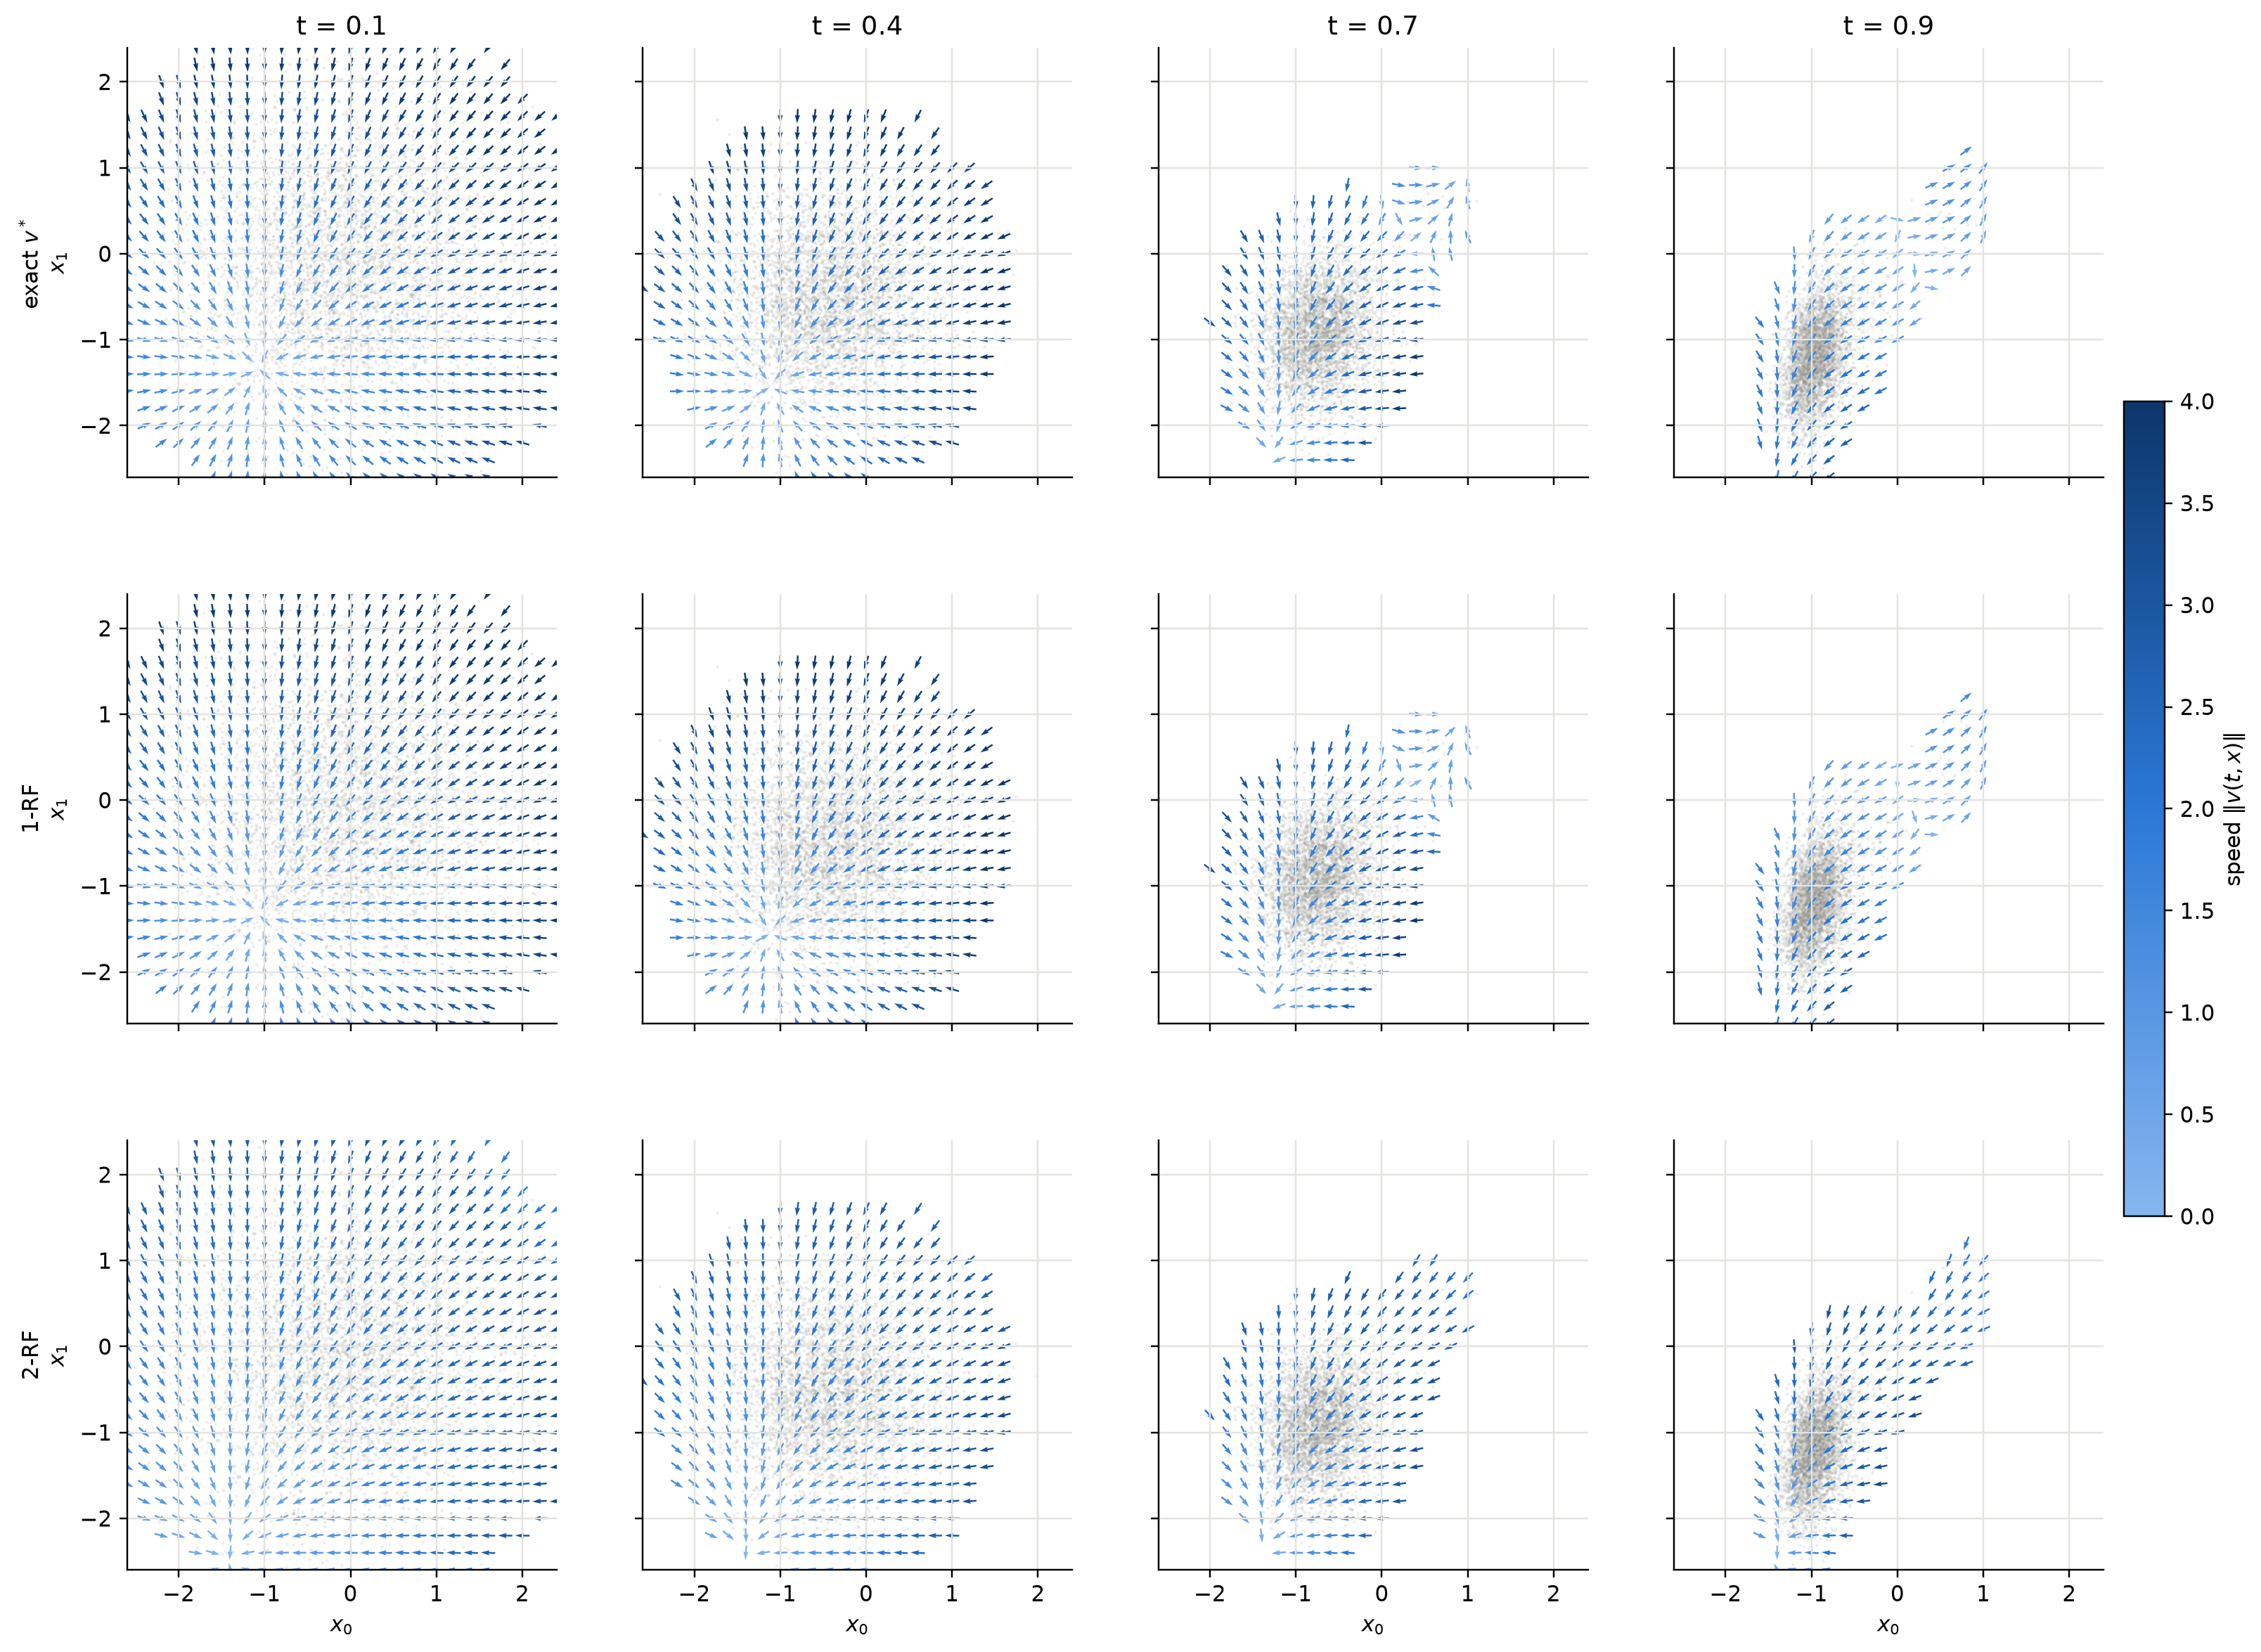

field error E|v - v*|^2 / E|v*|^2 against the exact 1-RF field
     t     0.02     0.05     0.10     0.20     0.30     0.40     0.50     0.60     0.70     0.80     0.90     0.95
1-RF    1.9e-05  5.9e-06  7.3e-06  1.2e-05  1.8e-05  1.1e-05  1.1e-05  4.3e-05  4.5e-05  5.3e-05  7.6e-05  4.6e-05
2-RF    5.5e-02  5.8e-02  5.7e-02  5.6e-02  5.0e-02  4.4e-02  3.3e-02  2.4e-02  2.4e-02  5.5e-02  1.8e-01  3.4e-01


saved: figures/field_error.png (+ .pdf)


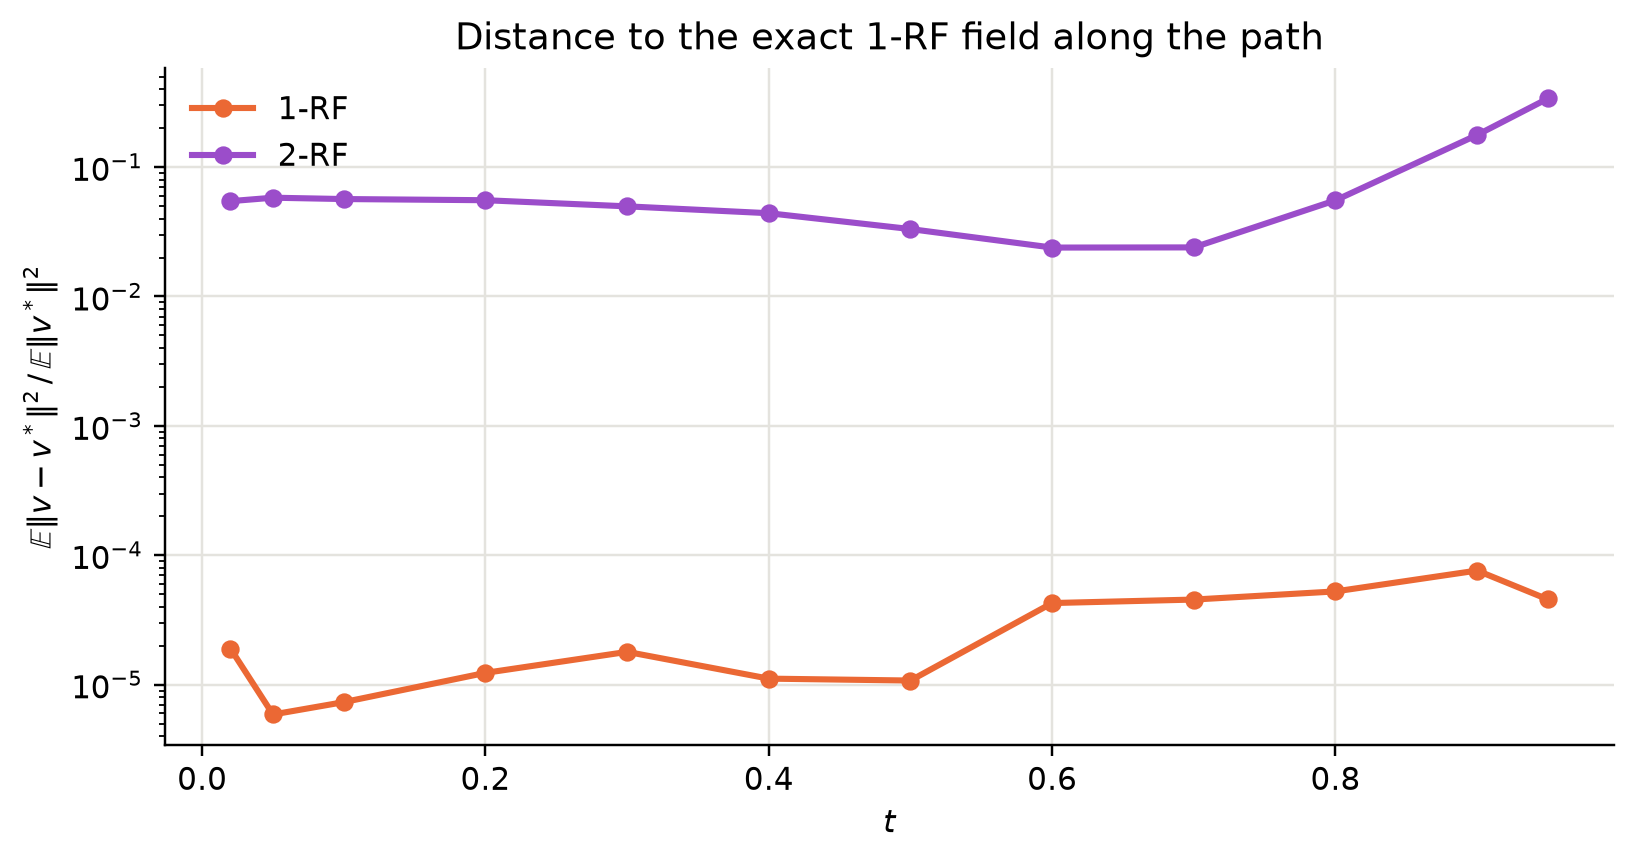

In [19]:
# 11.3 Velocity fields at four times and the field error against v*
# --- Step 1: exact field, 1-RF and 2-RF on a grid; arrows = direction, colour = speed ---
field_lim, m = (-2.6, 2.4), 26
axis = torch.linspace(*field_lim, m)
gx, gy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([gx.flatten(), gy.flatten()], 1).to(DEV)
z_field = torch.randn(CFG.n_eval, 2, generator=torch.Generator().manual_seed(3)).to(DEV)
fields = {"exact $v^*$": None, "1-RF": MODELS[1.0, 1], "2-RF": MODELS[1.0, 2]}
fig, axes = plt.subplots(3, 4, figsize=(17, 13), sharex=True, sharey=True)
for j, t in enumerate((0.1, 0.4, 0.7, 0.9)):
    xt = (t * X_REF[1.0] + (1 - t) * z_field).cpu().numpy()
    dx = float(axis[1] - axis[0])
    counts = np.histogram2d(xt[:, 0], xt[:, 1], bins=m, range=[[field_lim[0] - dx / 2, field_lim[1] + dx / 2]] * 2)[0]
    empty = counts.T.flatten() < 8                                    # cells without mass: no arrow
    for i, (name, model) in enumerate(fields.items()):
        with torch.no_grad():
            v = (exact_velocity(t, grid, 1.0).float() if model is None else model(t, grid)).cpu().numpy()
        speed = np.linalg.norm(v, axis=1)
        direction = v / np.maximum(speed, 1e-12)[:, None]
        direction[empty] = np.nan
        ax = axes[i, j]
        ax.scatter(xt[:4000, 0], xt[:4000, 1], s=2, alpha=0.15, color=COLORS["source"], linewidths=0, rasterized=True)
        arrows = ax.quiver(grid[:, 0].cpu().numpy(), grid[:, 1].cpu().numpy(), direction[:, 0], direction[:, 1],
                           speed, cmap=FIELD_CMAP, clim=(0, 4), pivot="mid", scale=30, width=0.004)
        ax.set(xlim=field_lim, ylim=field_lim, aspect="equal")
        if i == 0:
            ax.set_title(f"t = {t:g}")
        if j == 0:
            ax.set_ylabel(f"{name}\n$x_1$")
        if i == 2:
            ax.set_xlabel("$x_0$")
fig.colorbar(arrows, ax=axes, fraction=0.02, pad=0.01, label=r"speed $\|v(t, x)\|$")
save_figure(fig, "velocity_field")
plt.show()

# --- Step 2: field error against v* along the path ---
TS = [0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
FERR = cached("ferr_kT1.0", lambda: {k: field_error(MODELS[1.0, k], 1.0, X_REF[1.0], TS) for k in (1, 2)})
print("field error E|v - v*|^2 / E|v*|^2 against the exact 1-RF field")
print(f"{'t':>6}" + "".join(f"{t:>9.2f}" for t in TS))
for k in (1, 2):
    print(f"{k}-RF  " + "".join(f"{e:9.1e}" for e in FERR[k]))
fig, ax = plt.subplots(figsize=(8.5, 4))
for k in (1, 2):
    ax.semilogy(TS, FERR[k], "o-", color=COLORS[f"rf{k}"], lw=2, ms=5, label=f"{k}-RF")
ax.set(xlabel="$t$", ylabel=r"$\mathbb{E}\|v - v^*\|^2 \,/\, \mathbb{E}\|v^*\|^2$",
       title="Distance to the exact 1-RF field along the path")
ax.legend()
save_figure(fig, "field_error")
plt.show()

> **Observations.**
> - **$t = 0.1$:** the field still points from the noise towards the bulk of the data (left well), with speed growing with the distance.
> - **$t = 0.7$ and $t = 0.9$:** the exact field splits into two streams, one into each well; the dividing line between them is sharp.
> - **1-RF** cannot be told apart from the exact field on the maps; the field error is $6\cdot10^{-6}$–$8\cdot10^{-5}$ and grows towards $t = 1$, where the field has its sharpest structure — the split between the wells. The error is a mean square over the path and is dominated by the deep left well; the weight of the right well is checked separately (11.6).
> - **2-RF is a different field that generates the same distribution:** its error against $v^*$ is $2$–$6\,\%$ for $t \le 0.8$, $18\,\%$ at $t = 0.9$ and $34\,\%$ at $t = 0.95$. Its arrows are constant along straight lines and do not split at late times. So the learned velocity field is not unique: only for 1-RF there is one correct answer $v^*$; for 2-RF the right checks are the generated distribution (11.1) and the straightness (11.2).

### 11.4 Effect of the number of RK4 steps

**In this step**

1. **(a)** Generate samples with $N = 1, 2, 4, 8, 16$ uniform RK4 steps for 1-RF and 2-RF, all from the same noise points, and show them.
2. **(b)** For $N = 1, \dots, 128$ measure the solver error $e_N$ and the distance to the target (TV, $P(\text{right})$), print and plot them.

All runs start from the same $20\,000$ points of $Z_0$ and differ only in the number of steps $N$, i.e. in the step size $h = 1/N$ and in the cost of $4N$ network evaluations (NFE).

**Two kinds of error.**
- *Solver error*: how far the RK4 result is from the exact solution of the learned ODE, measured against a reference run with $N_{\text{ref}} = 512$ steps,

  $$e_N = \frac1n \sum_{i=1}^{n} \big\| Z_{1,i}^{(N)} - Z_{1,i}^{(N_{\text{ref}})} \big\| .$$

- *Distance to the target*: TV and $P(\text{right})$ against the exact distribution. The **noise level** of TV is the TV of an exact sample of the same size ($20\,000$ points).

**What to expect.** More steps reduce the solver error, but the generated distribution can never be better than the learned field: once $e_N$ is below the error of the network, additional steps no longer help. Straighter paths reach this point with fewer steps.

saved: figures/rk4_steps_samples.png (+ .pdf)


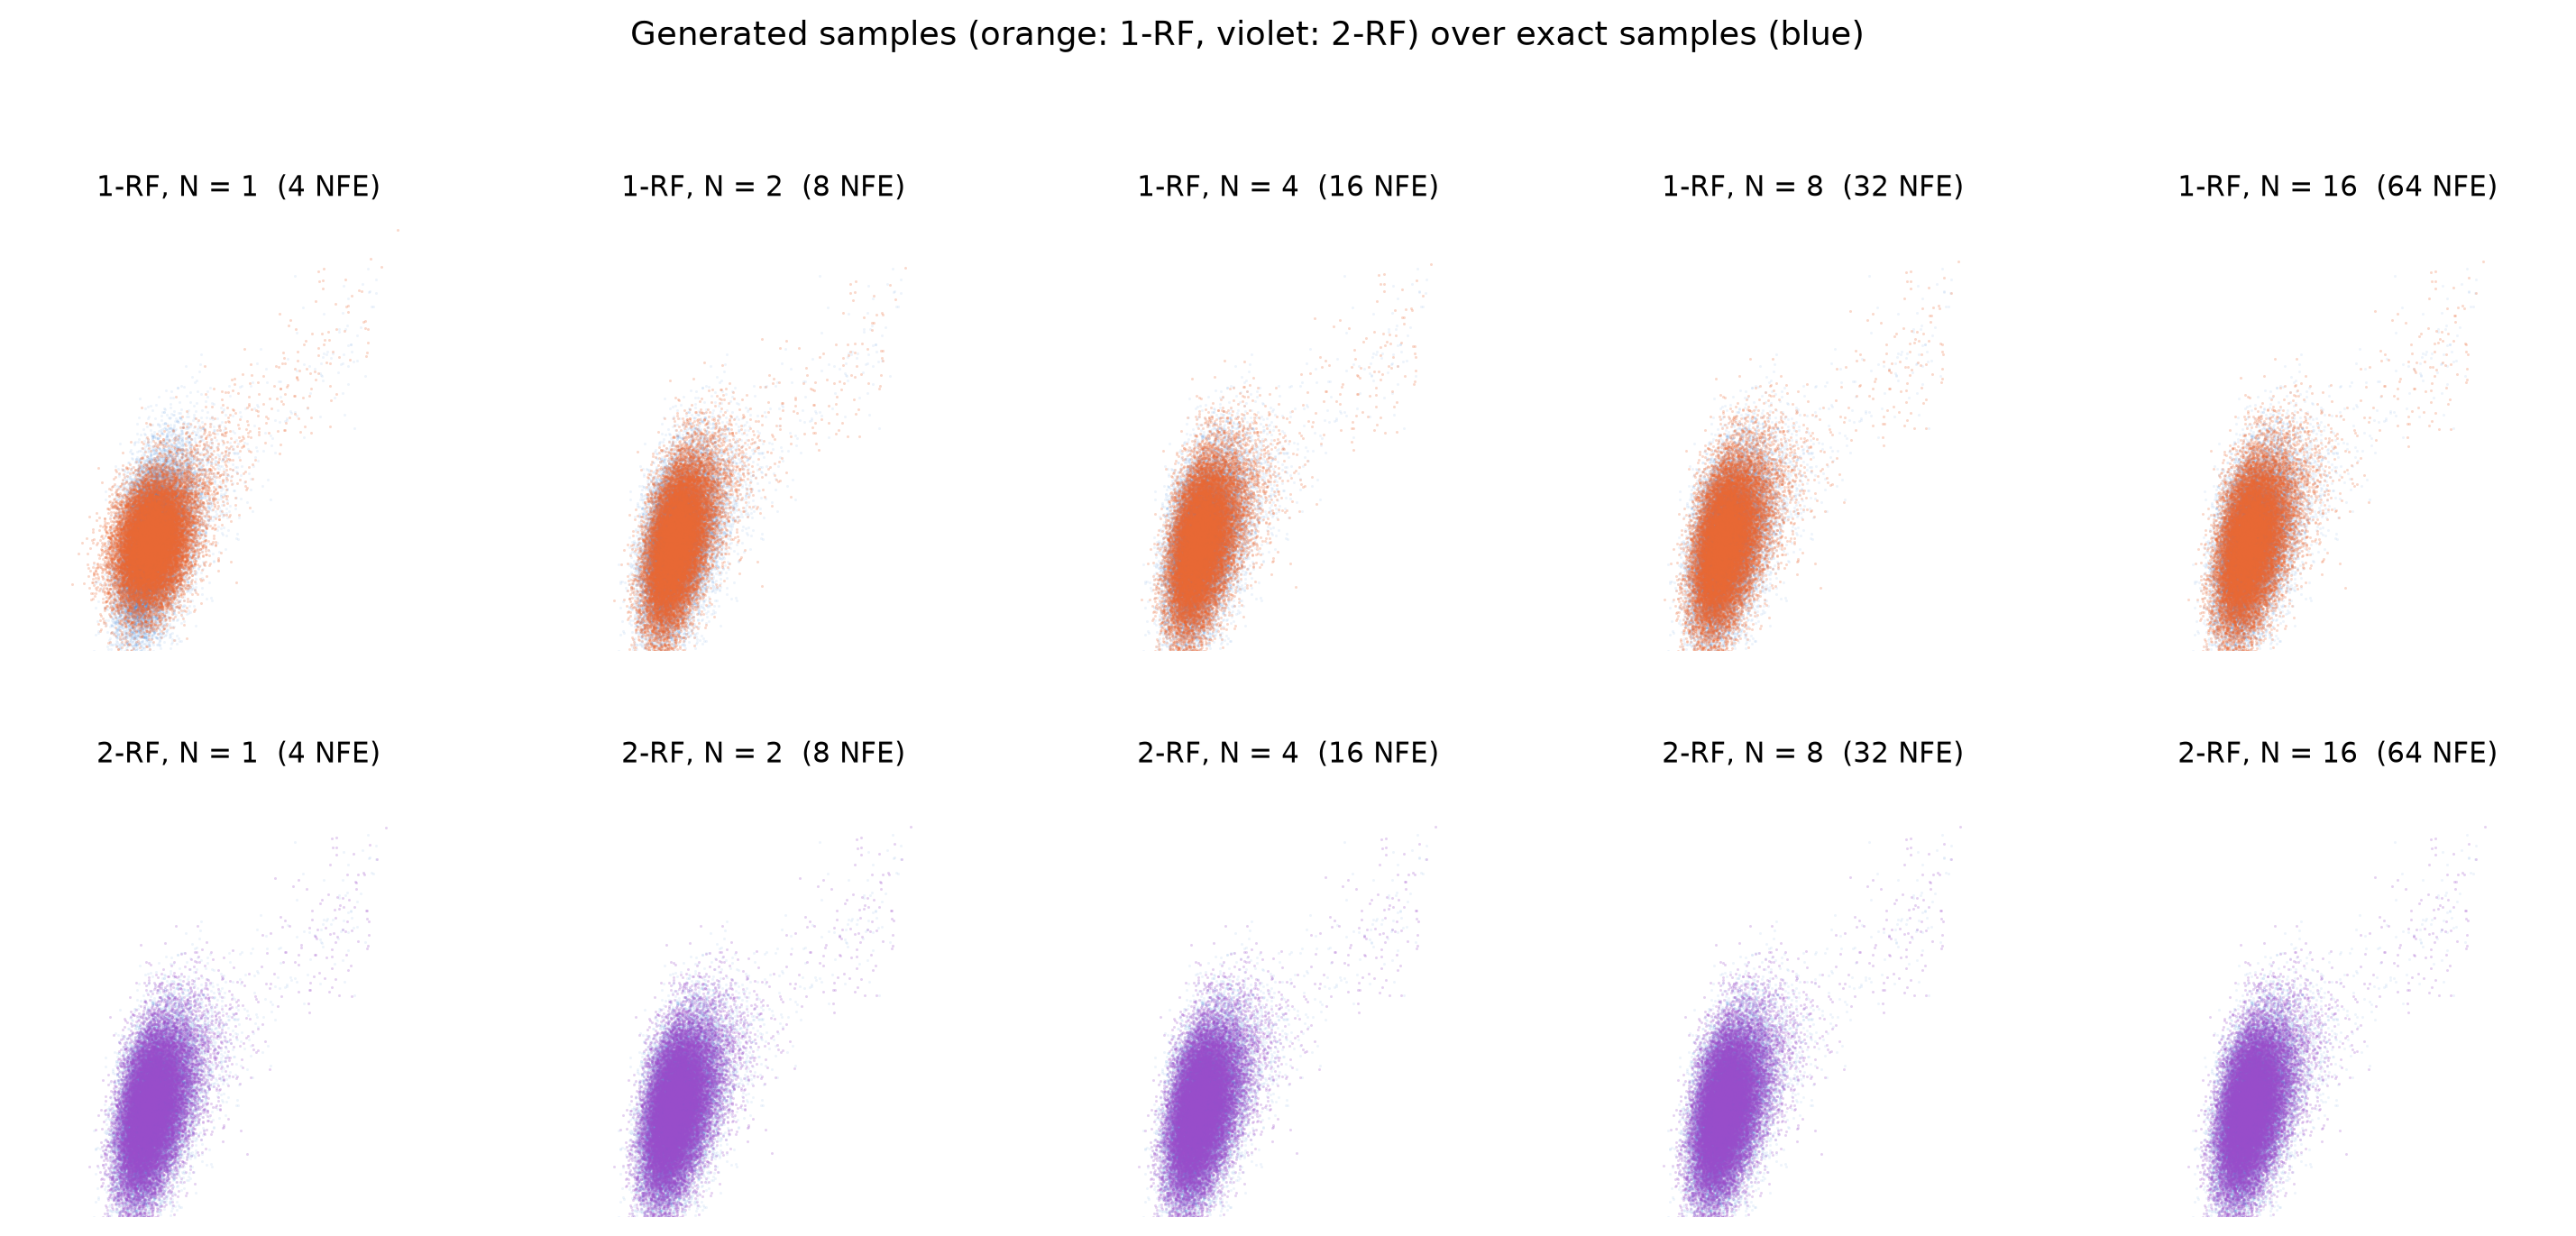

In [20]:
# 11.4 (a) Generated samples for N = 1 ... 16 RK4 steps, all from the same noise points
FEW_STEPS = (1, 2, 4, 8, 16)
FEW = cached("few_steps_kT1.0", lambda: {(k, n): rk4(MODELS[1.0, k], Z_SWEEP, n).cpu()
                                          for k in (1, 2) for n in FEW_STEPS})
fig, axes = plt.subplots(2, len(FEW_STEPS), figsize=(3.3 * len(FEW_STEPS), 6.8), sharex=True, sharey=True)
tgt = X_REF[1.0][:CFG.n_sweep].cpu().numpy()
for i, k in enumerate((1, 2)):
    for ax, n in zip(axes[i], FEW_STEPS):
        gen = FEW[k, n].numpy()
        ax.scatter(tgt[:, 0], tgt[:, 1], s=1, alpha=0.08, color=COLORS["target"], linewidths=0, rasterized=True)
        ax.scatter(gen[:, 0], gen[:, 1], s=1, alpha=0.25, color=COLORS[f"rf{k}"], linewidths=0, rasterized=True)
        ax.set(xlim=LIM, ylim=LIM, aspect="equal")
        ax.axis("off")
        ax.set_title(f"{k}-RF, N = {n}  ({4 * n} NFE)", fontsize=10)
fig.suptitle("Generated samples (orange: 1-RF, violet: 2-RF) over exact samples (blue)", y=1.01)
save_figure(fig, "rk4_steps_samples")
plt.show()

   N   NFE     1-RF e_N    1-RF TV     2-RF e_N    2-RF TV
   1     4     8.92e-02     0.0508     3.98e-04     0.0119
   2     8     1.70e-02     0.0441     1.32e-04     0.0122
   3    12     1.02e-02     0.0316     9.83e-05     0.0120
   4    16     5.68e-03     0.0196     7.51e-05     0.0120
   6    24     2.04e-03     0.0142     4.44e-05     0.0121
   8    32     1.15e-03     0.0132     4.14e-05     0.0119
  12    48     4.32e-04     0.0122     2.45e-05     0.0123
  16    64     1.34e-04     0.0118     2.02e-05     0.0122
  32   128     6.60e-06     0.0120     4.00e-06     0.0123
  64   256     5.65e-07     0.0120     5.25e-07     0.0123
 128   512     5.45e-07     0.0120     4.87e-07     0.0123
noise level of TV (exact sample, 20,000 points): 0.0120


saved: figures/rk4_steps_metrics.png (+ .pdf)


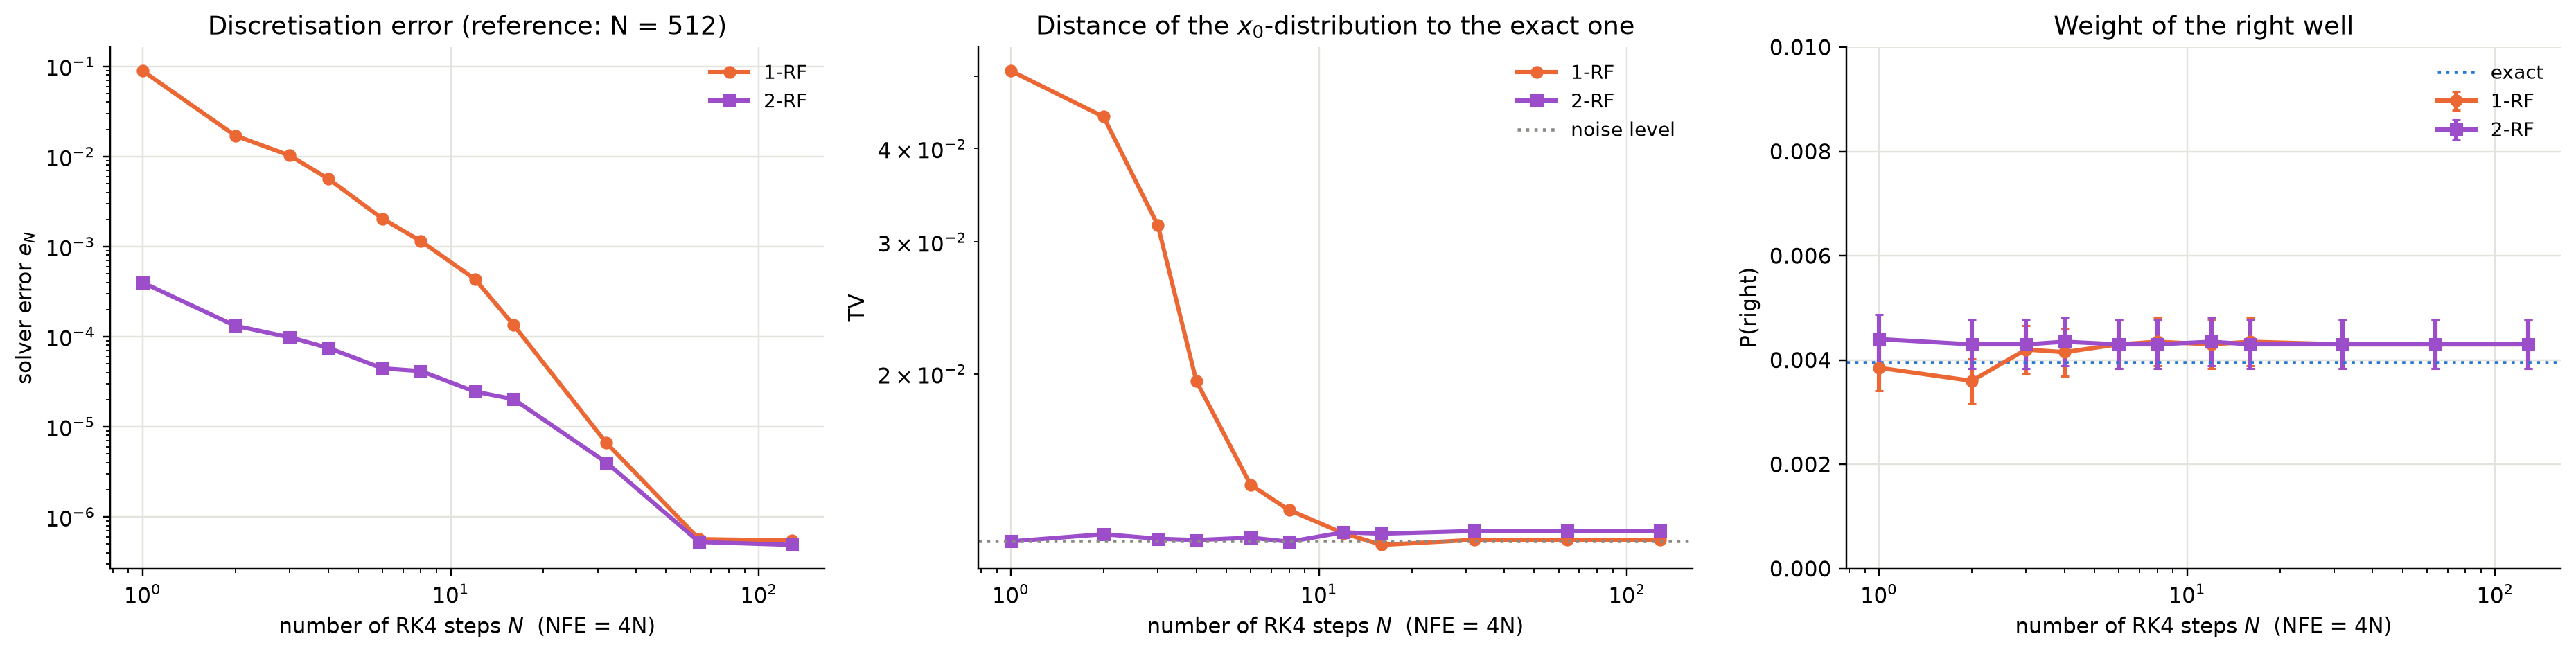

In [21]:
# 11.4 (b) Solver error e_N and distance to the target as functions of N
NS = [1, 2, 3, 4, 6, 8, 12, 16, 32, 64, 128]


def step_sweep():
    '''For 1-RF and 2-RF and every N: the four metrics and the solver error against N_ref = 512.'''
    out = {}
    for k in (1, 2):
        x_ref = rk4(MODELS[1.0, k], Z_SWEEP, CFG.ref_steps)
        for n in NS:
            x = rk4(MODELS[1.0, k], Z_SWEEP, n)
            out[k, n] = dict(score(x, 1.0, X_REF[1.0]), ode=(x - x_ref).norm(dim=1).mean().item())
    return out


SWEEP = cached("step_sweep_kT1.0", step_sweep)
NOISE_TV = score(X_CTRL[1.0][:CFG.n_sweep], 1.0, X_REF[1.0])["tv"]          # TV of an exact sample of this size

print(f"{'N':>4}{'NFE':>6}" + "".join(f"{f'{k}-RF e_N':>13}{f'{k}-RF TV':>11}" for k in (1, 2)))
for n in NS:
    print(f"{n:4d}{4 * n:6d}" + "".join(f"{SWEEP[k, n]['ode']:13.2e}{SWEEP[k, n]['tv']:11.4f}" for k in (1, 2)))
print(f"noise level of TV (exact sample, {CFG.n_sweep:,} points): {NOISE_TV:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for k, marker in zip((1, 2), ("o", "s")):
    color = COLORS[f"rf{k}"]
    axes[0].loglog(NS, [SWEEP[k, n]["ode"] for n in NS], marker + "-", color=color, lw=2, ms=5, label=f"{k}-RF")
    axes[1].loglog(NS, [SWEEP[k, n]["tv"] for n in NS], marker + "-", color=color, lw=2, ms=5, label=f"{k}-RF")
    axes[2].errorbar(NS, [SWEEP[k, n]["p_right"] for n in NS], [SWEEP[k, n]["p_se"] for n in NS],
                     fmt=marker + "-", color=color, lw=2, ms=5, capsize=2, label=f"{k}-RF")
axes[1].axhline(NOISE_TV, ls=":", lw=1.5, color=COLORS["source"], label="noise level")
axes[2].axhline(REF[1.0]["p_right"], ls=":", lw=1.5, color=COLORS["target"], label="exact")
axes[2].set_xscale("log")
axes[0].set(ylabel="solver error $e_N$",
            title=f"Discretisation error (reference: N = {CFG.ref_steps})")
axes[1].set(ylabel="TV", title="Distance of the $x_0$-distribution to the exact one")
axes[2].set(ylabel="P(right)", ylim=(0, 0.01), title="Weight of the right well")
for ax in axes:
    ax.set_xlabel("number of RK4 steps $N$  (NFE = 4N)")
    ax.legend(fontsize=9)
fig.tight_layout()
save_figure(fig, "rk4_steps_metrics")
plt.show()

> **Observations.**
> - **1-RF with few steps.** With one step the samples are clearly wrong — the cloud is smeared and shifted (TV $= 0.051$, solver error $0.089$). With $N = 2$–$4$ the shape appears but the tail towards the right well is still distorted. TV reaches the noise level ($\approx 0.012$ for $20\,000$ points) at $N \approx 12$–$16$, i.e. $50$–$60$ network evaluations.
> - **Solver error of 1-RF** falls steeply with $N$ and reaches the rounding precision of float32 numbers ($\approx 5\cdot10^{-7}$) at $N = 64$; this also shows that the reference with $N_{\text{ref}} = 512$ is accurate enough.
> - **2-RF with one step** is already at the noise level of TV, with solver error $4\cdot10^{-4}$: RK4 is exact for straight paths travelled at constant speed. Reflow buys a $12$–$16$-fold reduction of the sampling cost — $4$ network evaluations instead of $50$–$60$.
> - **$P(\text{right})$** is the least sensitive measure here: $20\,000$ points hold only about $80$ right-well samples, and the error bars cover all $N$.

### 11.5 Placement of the time steps

**In this step**

1. For a fixed budget of $N = 2, 4, 8, 16$ RK4 steps, compare the four time grids of Section 8 (uniform, late, early, cosine) for 1-RF and 2-RF: solver error against $N_{\text{ref}} = 512$ and TV, on $20\,000$ points.
2. Print the table and plot the solver error together with the four grids.

**Idea.** The steps should be short where the paths bend. Section 11.2 showed that 1-RF bends late, near the data.

1-RF                         N = 2             N = 4             N = 8            N = 16
                       e_N      TV       e_N      TV       e_N      TV       e_N      TV
  uniform         1.70e-02  0.0441  5.68e-03  0.0196  1.15e-03  0.0132  1.34e-04  0.0118
  late            7.64e-03  0.0137  1.19e-03  0.0122  6.10e-04  0.0120  1.33e-04  0.0121
  early           4.51e-02  0.0441  1.52e-02  0.0424  4.69e-03  0.0178  1.05e-03  0.0129
  cosine          1.70e-02  0.0441  2.87e-03  0.0109  8.64e-04  0.0121  2.01e-04  0.0120
2-RF                         N = 2             N = 4             N = 8            N = 16
                       e_N      TV       e_N      TV       e_N      TV       e_N      TV
  uniform         1.32e-04  0.0122  7.51e-05  0.0120  4.14e-05  0.0119  2.02e-05  0.0122
  late            9.82e-05  0.0119  5.26e-05  0.0121  2.80e-05  0.0123  1.41e-05  0.0123
  early           1.78e-04  0.0122  9.38e-05  0.0122  5.77e-05  0.0121  3.44e-05  0.0120
  cosine          1.3

saved: figures/time_grids.png (+ .pdf)


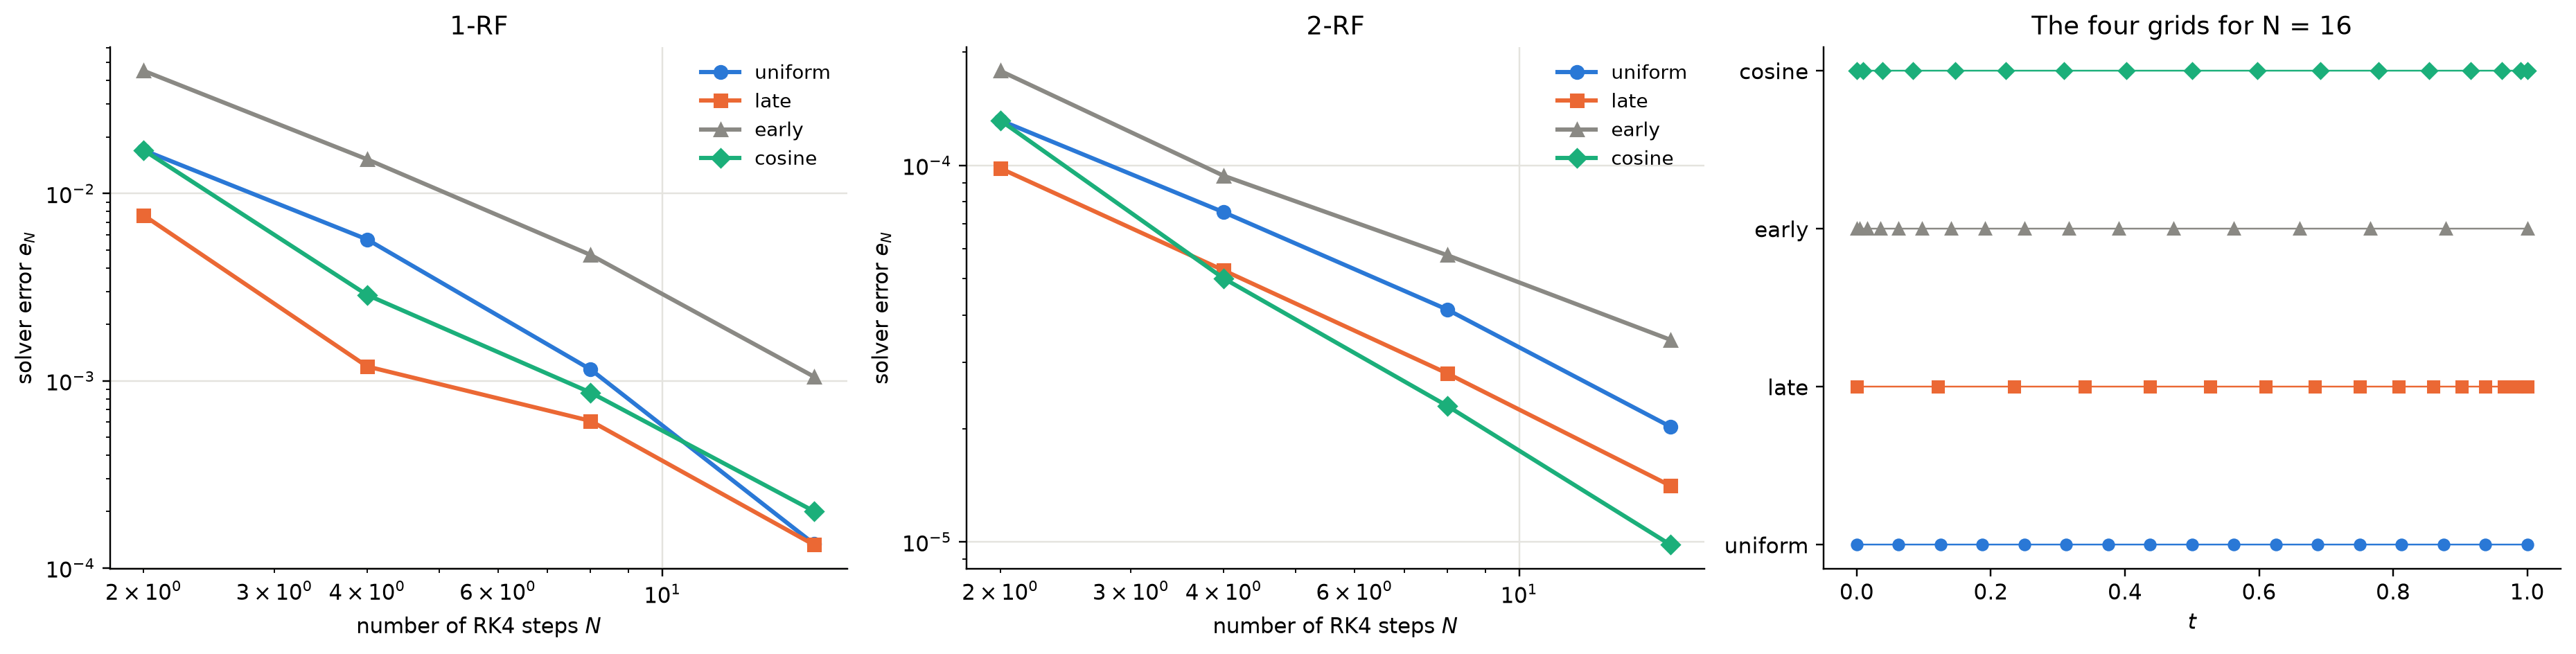

In [22]:
# 11.5 Placement of the time steps: four grids for a fixed number of RK4 steps
GRIDS, NG = ("uniform", "late", "early", "cosine"), (2, 4, 8, 16)


def grid_sweep():
    '''Solver error and TV for every model, grid and N.'''
    out = {}
    for k in (1, 2):
        x_ref = rk4(MODELS[1.0, k], Z_SWEEP, CFG.ref_steps)
        for gname in GRIDS:
            for n in NG:
                x = rk4(MODELS[1.0, k], Z_SWEEP, n, gname)
                out[k, gname, n] = dict(ode=(x - x_ref).norm(dim=1).mean().item(), tv=score(x, 1.0, X_REF[1.0])["tv"])
    return out


GERR = cached("grid_sweep_kT1.0", grid_sweep)
for k in (1, 2):
    print(f"{k}-RF" + " " * 12 + "".join(f"{f'N = {n}':>18}" for n in NG))
    print(" " * 16 + "".join(f"{'e_N':>10}{'TV':>8}" for n in NG))
    for gname in GRIDS:
        print(f"  {gname:14}" + "".join(f"{GERR[k, gname, n]['ode']:10.2e}{GERR[k, gname, n]['tv']:8.4f}" for n in NG))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
markers = dict(uniform="o", late="s", early="^", cosine="D")
grid_colors = dict(uniform=COLORS["target"], late=COLORS["rf1"], early=COLORS["source"], cosine=COLORS["data"])
for ax, k in zip(axes, (1, 2)):
    for gname in GRIDS:
        ax.loglog(NG, [GERR[k, gname, n]["ode"] for n in NG], markers[gname] + "-", color=grid_colors[gname],
                  lw=2, ms=6, label=gname)
    ax.set(xlabel="number of RK4 steps $N$", ylabel="solver error $e_N$",
           title=f"{k}-RF")
    ax.legend(fontsize=9)
for row, gname in enumerate(GRIDS):
    axes[2].plot(time_grid(16, gname), np.full(17, row), markers[gname] + "-", color=grid_colors[gname], lw=0.8, ms=5)
axes[2].set_yticks(range(len(GRIDS)), GRIDS)
axes[2].set(xlabel="$t$", title="The four grids for N = 16")
axes[2].grid(False)
fig.tight_layout()
save_figure(fig, "time_grids")
plt.show()

> **Observations.**
> - **For 1-RF the placement matters at small $N$.** With the *late* grid the solver error is $7.6\cdot10^{-3}$ at $N = 2$ and $1.2\cdot10^{-3}$ at $N = 4$, against $1.7\cdot10^{-2}$ and $5.7\cdot10^{-3}$ for the uniform grid — $2$–$5$ times smaller; TV at $N = 2$ drops from $0.044$ to $0.014$.
> - The *early* grid is the worst ($4.5\cdot10^{-2}$ at $N = 2$): it spends the steps where the paths are almost straight. *Cosine* coincides with the uniform grid at $N = 2$ and lies in between at $N = 4$.
> - At $N = 16$ all grids except *early* agree ($\approx 1.3$–$2\cdot10^{-4}$).
> - **For 2-RF** every grid gives errors $\le 2\cdot10^{-4}$ at every $N$: a straight flow has nothing to resolve. A good time grid is therefore a cheap partial substitute for reflow, but only at very small $N$.

### 11.6 Temperature: $k_BT = 0.5,\ 1,\ 2$

**In this step**

1. Print the four metrics of the Monte Carlo data, 1-RF, 2-RF and 2-RF with a single RK4 step at each temperature, and the straightness of 1-RF and 2-RF.
2. Plot the $x_0$-distributions, the field error of 1-RF and the straightness against the temperature.
3. **Rare-event check.** At $k_BT = 0.5$ the right well holds $1.1\cdot10^{-5}$ of the mass: $200\,000$ points contain about two of them, too few to say anything. 2-RF is straight, so one RK4 step (4 network evaluations) reproduces its samples, and $10^7$ samples cost seconds. Count the right-well samples among $10^7$ and compare with the exact weight and the Monte Carlo estimate.

k_BT = 0.5:  exact  P(right) = 1.148e-05,  <V> = -2.8464
                                      P(right) ± s.e.   count    rel.      z      TV      <V>   ED·1e3
exact control (noise)            1.000e-05 ± 7.1e-06       2    -13%   -0.2  0.0025  -2.8469    0.025
Monte Carlo data                 2.000e-05 ± 1.4e-05       2    +74%   +0.8  0.0040  -2.8463   -0.027
1-RF (RK4, N = 50)               0.000e+00 ± 0.0e+00       0   -100%   -1.5  0.0042  -2.8472    0.080
2-RF (RK4, N = 50)               0.000e+00 ± 0.0e+00       0   -100%   -1.5  0.0042  -2.8472    0.080
2-RF (RK4, N = 1)                0.000e+00 ± 0.0e+00       0   -100%   -1.5  0.0062  -2.8433    0.077

k_BT = 1:  exact  P(right) = 3.957e-03,  <V> = -2.2812
                                      P(right) ± s.e.   count    rel.      z      TV      <V>   ED·1e3
exact control (noise)            4.005e-03 ± 1.4e-04     801     +1%   +0.3  0.0032  -2.2808   -0.057
Monte Carlo data                 4.050e-03 ± 2.0e-04     405     +2% 

saved: figures/temperature_x0.png (+ .pdf)


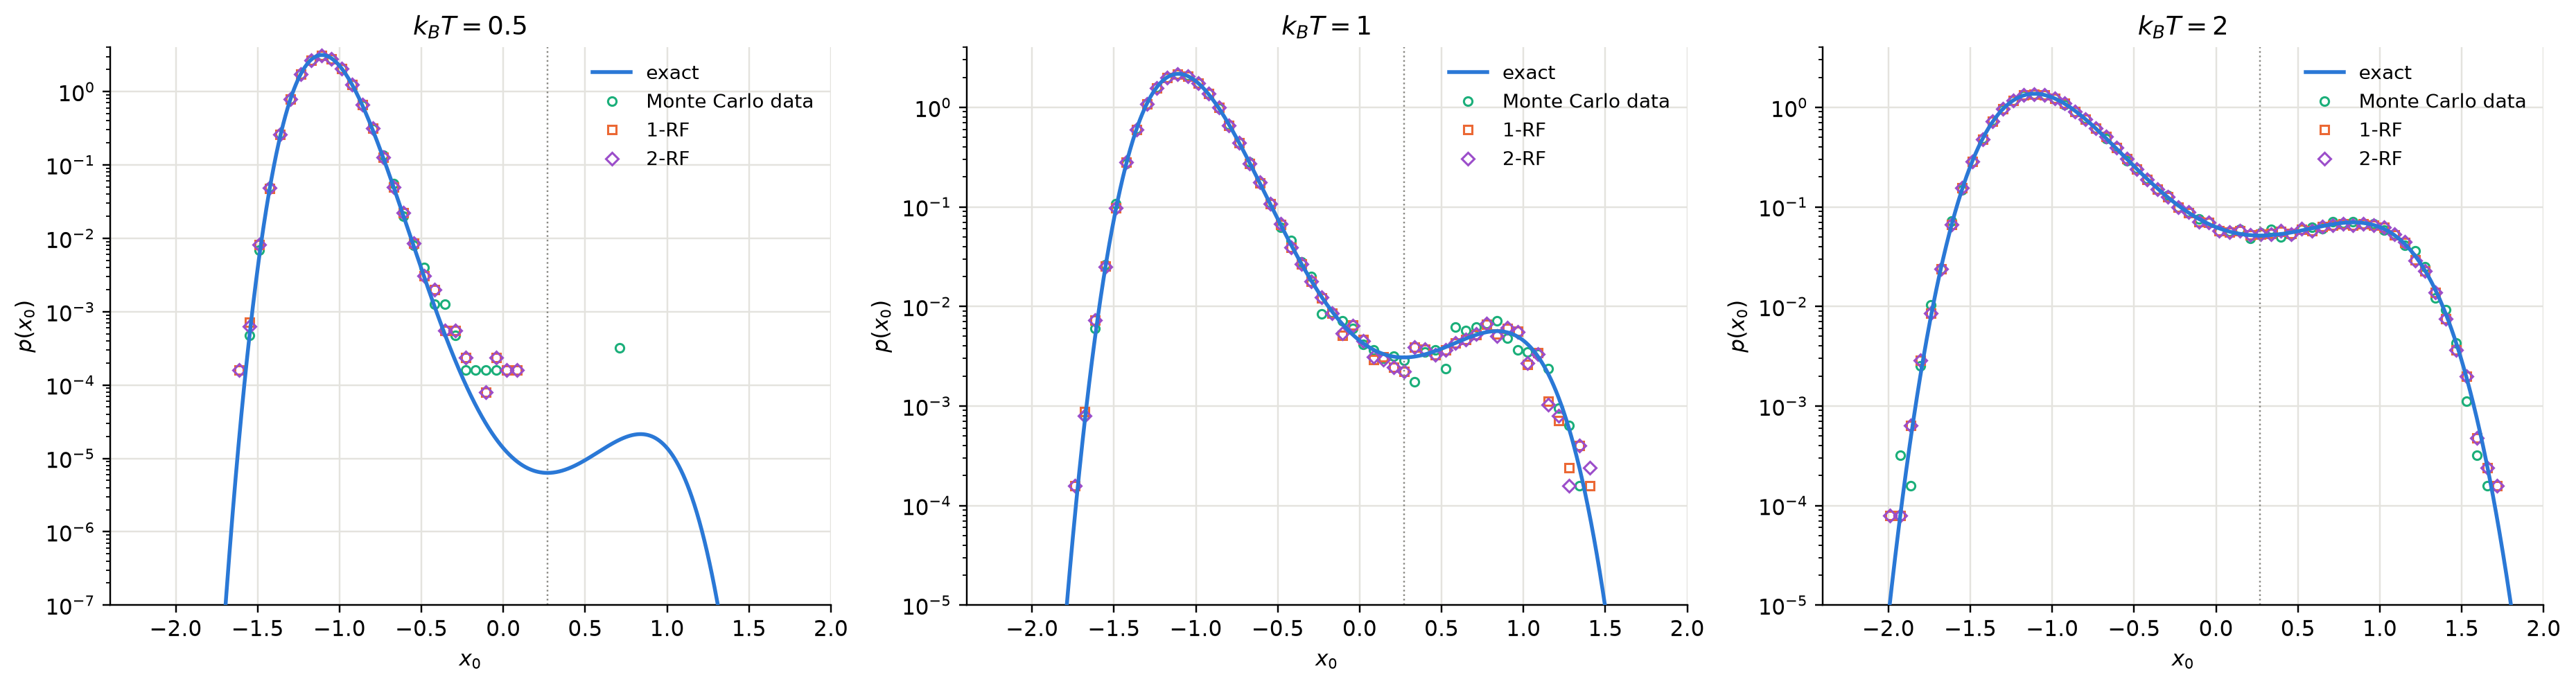

saved: figures/temperature_field.png (+ .pdf)


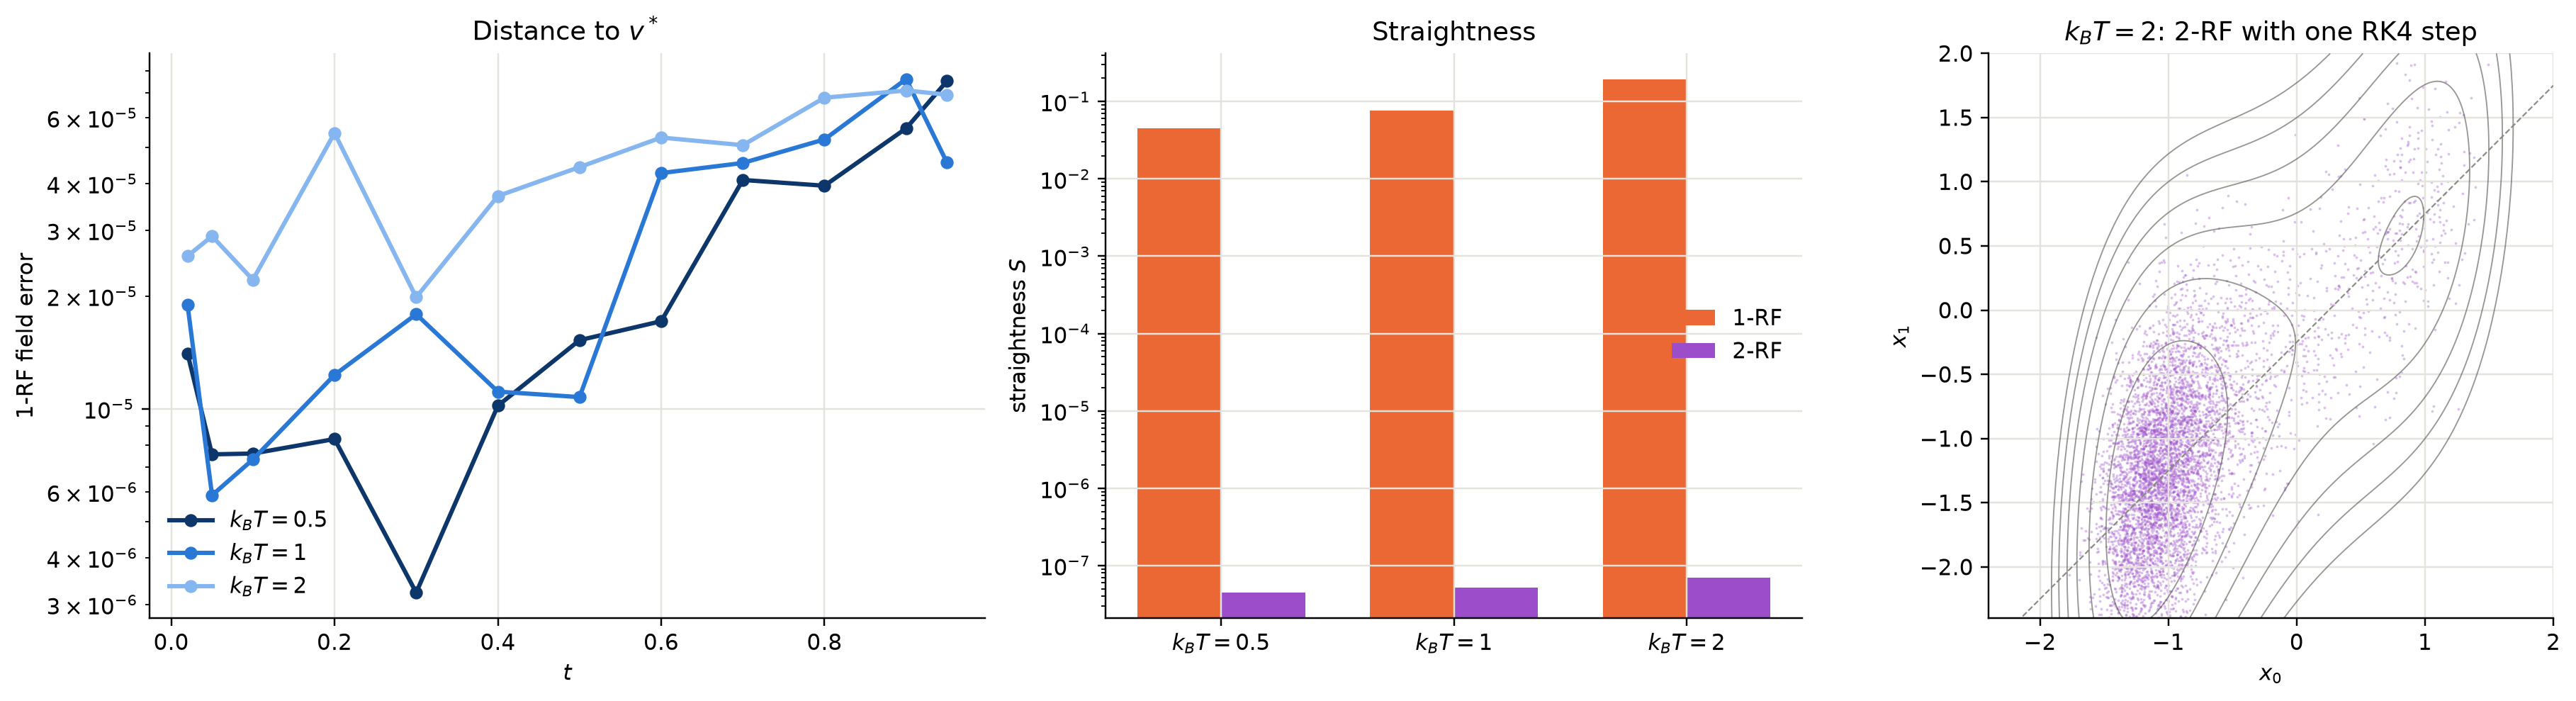


   kT       exact        MC chains ± s.e.     2-RF, 1 step, 10^7 points    count      z
  0.5   1.148e-05    2.583e-05 ±  2.8e-05          4.800e-06 ±  6.9e-07       48   -6.2
  1.0   3.957e-03    4.092e-03 ±  2.6e-04          4.142e-03 ±  2.0e-05    41421   +9.3
  2.0   5.978e-02    5.986e-02 ±  7.1e-04          5.983e-02 ±  7.5e-05   598311   +0.7


In [23]:
# 11.6 Temperature dependence
# --- Step 1: metrics and straightness at every temperature ---
TSTAT = {kT: cached(f"stats_kT{kT}", lambda: dict(
    ferr=field_error(MODELS[kT, 1], kT, X_REF[kT], TS),
    s1=straightness(MODELS[kT, 1], Z_SWEEP), s2=straightness(MODELS[kT, 2], Z_SWEEP))) for kT in TEMPS}
for kT in TEMPS:
    table({"Monte Carlo data": score(MC[kT].data, kT, X_REF[kT]),
           f"1-RF (RK4, N = {CFG.rk4_steps})": score(GEN[kT, 1], kT, X_REF[kT]),
           f"2-RF (RK4, N = {CFG.rk4_steps})": score(GEN[kT, 2], kT, X_REF[kT]),
           "2-RF (RK4, N = 1)": score(GEN[kT, "2-RF, 1 step"], kT, X_REF[kT])}, kT)
    print()
print(f"{'kT':>5}{'S(1-RF)':>11}{'S(2-RF)':>11}")
for kT in TEMPS:
    print(f"{kT:5.1f}{TSTAT[kT]['s1']:11.2e}{TSTAT[kT]['s2']:11.2e}")

# --- Step 2: x_0-distributions, field error and straightness ---
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, kT in zip(axes, TEMPS):
    x0_profile(ax, {"Monte Carlo data": (MC[kT].data, COLORS["data"]),
                    "1-RF": (GEN[kT, 1], COLORS["rf1"]), "2-RF": (GEN[kT, 2], COLORS["rf2"])}, kT)
    ax.set_ylim(1e-7 if kT == 0.5 else 1e-5, 4)
    ax.set_title(f"$k_BT = {kT:g}$")
    ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
save_figure(fig, "temperature_x0")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1, 1]))
for kT in TEMPS:
    axes[0].semilogy(TS, TSTAT[kT]["ferr"], "o-", color=TEMP_COLORS[kT], lw=2, ms=5, label=f"$k_BT = {kT:g}$")
axes[0].set(xlabel="$t$", ylabel="1-RF field error", title="Distance to $v^*$")
axes[0].legend()
xs = np.arange(len(TEMPS))
axes[1].bar(xs - 0.18, [TSTAT[kT]["s1"] for kT in TEMPS], 0.36, color=COLORS["rf1"], label="1-RF")
axes[1].bar(xs + 0.18, [TSTAT[kT]["s2"] for kT in TEMPS], 0.36, color=COLORS["rf2"], label="2-RF")
axes[1].set_xticks(xs, [f"$k_BT = {kT:g}$" for kT in TEMPS])
axes[1].set(yscale="log", ylabel="straightness $S$", title="Straightness")
axes[1].legend(loc="center right")
cloud(axes[2], GEN[2.0, "2-RF, 1 step"], COLORS["rf2"], kT=2.0)
axes[2].set_title("$k_BT = 2$: 2-RF with one RK4 step")
fig.tight_layout()
save_figure(fig, "temperature_field")
plt.show()

# --- Step 3: weight of the right well from 10^7 one-step samples of 2-RF ---
N_BIG = 10_000_000


def right_well_count(kT: float) -> int:
    '''Number of right-well samples among N_BIG one-step 2-RF samples (in 10 chunks).'''
    count = 0
    for c in range(10):
        z = torch.randn(N_BIG // 10, 2, generator=torch.Generator().manual_seed(500 + c)).to(DEV)
        count += (rk4(MODELS[kT, 2], z, 1)[:, 0] > X_SADDLE).sum().item()
    return count


print(f"\n{'kT':>5}{'exact':>12}{'MC chains ± s.e.':>24}"
      f"{'2-RF, 1 step, 10^7 points':>30}{'count':>9}{'z':>7}")
for kT in TEMPS:
    count = cached(f"right_well_count_kT{kT}", lambda: right_well_count(kT))
    p, p0 = count / N_BIG, REF[kT]["p_right"]
    mc, mc_se = MC[kT].estimates["p_right"]
    print(f"{kT:5.1f}{p0:12.3e}{mc:13.3e} ± {mc_se:8.1e}{p:19.3e} ± {(p * (1 - p) / N_BIG) ** 0.5:8.1e}"
          f"{count:9d}{(p - p0) / (p0 * (1 - p0) / N_BIG) ** 0.5:+7.1f}")

> **Observations.**
>
> | $k_BT$ | barrier / $k_BT$ | right-well points in the training set | $S$(1-RF) | $S$(2-RF) | $P(\text{right})$: exact | 2-RF, 1 step, $10^7$ points |
> |---|---|---|---|---|---|---|
> | 0.5 | 13.1 | 2 | $4.5\cdot10^{-2}$ | $4\cdot10^{-8}$ | $1.15\cdot10^{-5}$ | $0.48\cdot10^{-5}$ ($-58\,\%$) |
> | 1 | 6.6 | 405 | $7.7\cdot10^{-2}$ | $5\cdot10^{-8}$ | $3.96\cdot10^{-3}$ | $4.14\cdot10^{-3}$ ($+4.7\,\%$) |
> | 2 | 3.3 | 6035 | $2.0\cdot10^{-1}$ | $7\cdot10^{-8}$ | $5.98\cdot10^{-2}$ | $5.98\cdot10^{-2}$ ($+0.1\,\%$) |
>
> - **Bulk of the distribution.** At $k_BT = 1$ and $2$ 1-RF and 2-RF agree with the exact distribution ($|z| \le 1.2$, TV at the noise level); at $k_BT = 2$ $\langle V \rangle$ is about $0.01$ too low. The field error of 1-RF stays between $3\cdot10^{-6}$ and $8\cdot10^{-5}$ at every temperature, slightly larger at $k_BT = 2$: shape and field are learned equally well at all three temperatures.
> - **Straightness.** At higher temperature the target is broader and truly two-humped: more noise has to be divided between the wells, the straight lines cross more, and 1-RF bends more ($S$ grows 4 times from $k_BT = 0.5$ to $2$). One reflow straightens all three flows, and 2-RF with a single step reproduces the distribution even at $k_BT = 2$.
> - **The rare well — here the temperature matters, and the limit is the data, not the flow.** The $10^7$ one-step samples fix the right-well weight of the model to $\pm 0.5\,\%$. At $k_BT = 1$ the deviation ($+4.7\,\%$) is within the sampling uncertainty of the $405$ right-well training points ($\pm 5\,\%$). At $k_BT = 0.5$ the training set holds two right-well configurations, and the flow turns them into a well with $40\,\%$ of the correct weight — in the right place, but with a weight it had no way to learn.
> - A flow trained on Monte Carlo data cannot be more accurate than the data: for a barrier of $13\,k_BT$ the bottleneck is sampling.

### 11.7 Number of training samples

**In this step**

1. Print the four metrics of 1-RF trained at $k_BT = 1$ on the first $n = 1\,000$, $10\,000$ and $100\,000$ Monte Carlo configurations (same network, same $20\,000$ iterations).
2. Plot, for every $n$, the generated samples together with the training points (top row), the $x_0$-distributions and the field error (bottom row).

k_BT = 1:  exact  P(right) = 3.957e-03,  <V> = -2.2812
                                      P(right) ± s.e.   count    rel.      z      TV      <V>   ED·1e3
exact control (noise)            4.005e-03 ± 1.4e-04     801     +1%   +0.3  0.0032  -2.2808   -0.057
1-RF, n = 1,000                  4.435e-03 ± 1.5e-04     887    +12%   +3.4  0.0306  -2.2494   -0.006
1-RF, n = 10,000                 3.610e-03 ± 1.3e-04     722     -9%   -2.5  0.0074  -2.2894   -0.104
1-RF, n = 100,000                3.890e-03 ± 1.4e-04     778     -2%   -0.5  0.0042  -2.2851    0.116


saved: figures/training_size.png (+ .pdf)


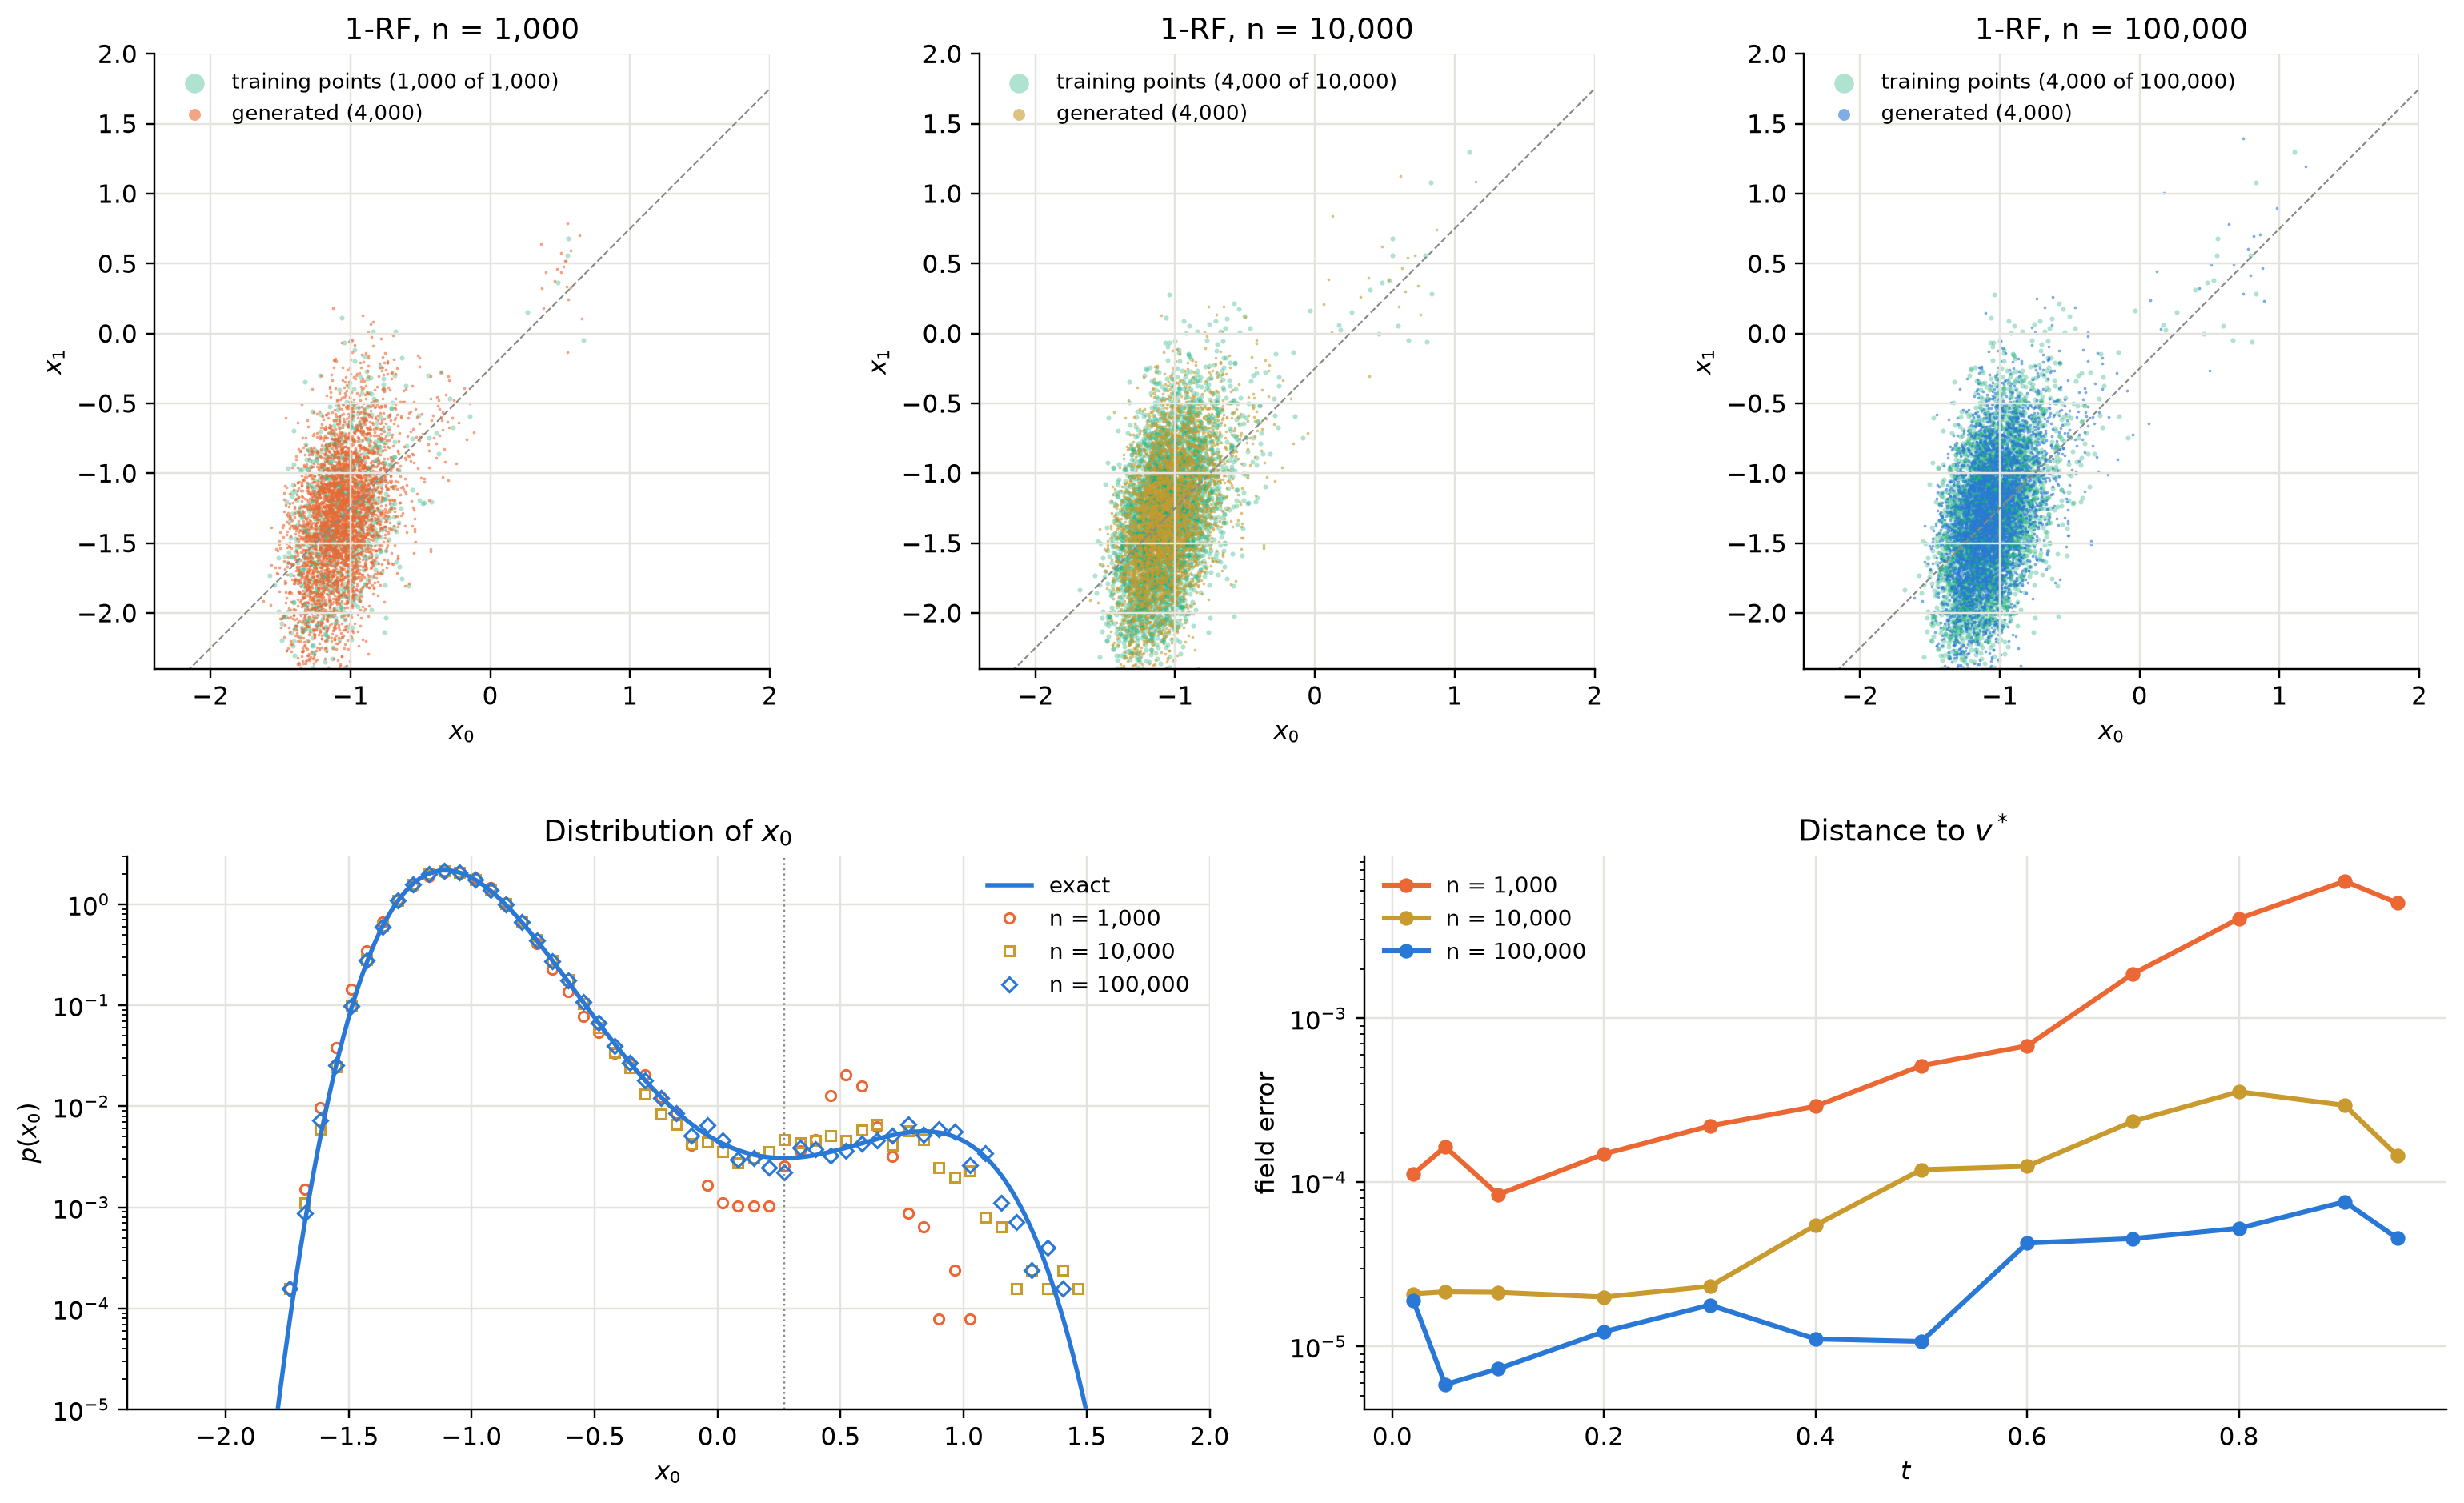

In [24]:
# 11.7 Number of training samples
SIZES = CFG.train_sizes
# --- Step 1: metrics ---
for n in SIZES:
    FERR["n", n] = cached(f"ferr_kT1.0_n{n}", lambda: field_error(MODELS["n", n], 1.0, X_REF[1.0], TS))
table({f"1-RF, n = {n:,d}": score(GEN["n", n], 1.0, X_REF[1.0]) for n in SIZES}, 1.0)

# --- Step 2: generated samples and training points for every n, x_0-distributions, field error ---
size_colors = dict(zip(SIZES, (COLORS["rf1"], "#c99a2e", COLORS["target"])))
fig = plt.figure(figsize=(17, 10))
gs = fig.add_gridspec(2, 6, height_ratios=[1, 0.9], hspace=0.32, wspace=0.6)
for j, n in enumerate(SIZES):
    ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
    pts = MC[1.0].data[:n][:4000].numpy()                              # training points (at most 4000 shown)
    gen = GEN["n", n][:4000].cpu().numpy()                             # generated points
    ax.scatter(pts[:, 0], pts[:, 1], s=4, color=COLORS["data"], alpha=0.35, linewidths=0, rasterized=True,
               label=f"training points ({len(pts):,d} of {n:,d})")
    ax.scatter(gen[:, 0], gen[:, 1], s=1.5, color=size_colors[n], alpha=0.6, linewidths=0, rasterized=True,
               label="generated (4,000)")
    ax.plot(LIM, [LIM[0] - D / 2, LIM[1] - D / 2], color=COLORS["source"], lw=0.7, ls="--")
    ax.set(xlim=LIM, ylim=LIM, aspect="equal", xlabel="$x_0$", ylabel="$x_1$", title=f"1-RF, n = {n:,d}")
    ax.legend(loc="upper left", fontsize=8.5, markerscale=4)
ax = fig.add_subplot(gs[1, :3])
x0_profile(ax, {f"n = {n:,d}": (GEN["n", n], size_colors[n]) for n in SIZES}, 1.0)
ax.set_title("Distribution of $x_0$")
ax.legend(loc="upper right", fontsize=9)
ax = fig.add_subplot(gs[1, 3:])
for n in SIZES:
    ax.semilogy(TS, FERR["n", n], "o-", color=size_colors[n], lw=2, ms=5, label=f"n = {n:,d}")
ax.set(xlabel="$t$", ylabel="field error", title="Distance to $v^*$")
ax.legend(fontsize=9)
save_figure(fig, "training_size")
plt.show()

> **Observations.**
>
> | $n$ | right-well points in the data | TV | $P(\text{right})$ | $\langle V \rangle$ (exact $-2.281$) | field error |
> |---|---|---|---|---|---|
> | 1 000 | 4 | 0.031 | $+12\,\%$ ($z = +3.4$) | $-2.249$ | $8\cdot10^{-5}$–$7\cdot10^{-3}$ |
> | 10 000 | 40 | 0.0074 | $-9\,\%$ ($z = -2.5$) | $-2.289$ | $2\cdot10^{-5}$–$4\cdot10^{-4}$ |
> | 100 000 | 405 | 0.0042 | $-2\,\%$ ($z = -0.5$) | $-2.285$ | $6\cdot10^{-6}$–$8\cdot10^{-5}$ |
>
> - The field error falls by about an order of magnitude from $1\,000$ to $10\,000$ points and by $2$–$5$ times from $10\,000$ to $100\,000$, and is again largest late in the path.
> - **$n = 1\,000$:** the left well is learned well, but the right well is built from four points: the $x_0$-distribution shows bumps of density around these points instead of a smooth well, and in the sparse region the generated cloud follows the individual training points. The cloud is also too wide overall ($\langle V \rangle$ too high by $0.03$; TV about $10$ times the noise).
> - **$n = 10\,000$** is already close; at **$n = 100\,000$** every metric is at the noise level.
> - The weight of the rare well converges last — it needs the most data, exactly like the Monte Carlo estimate itself.

## 12. Discussion and conclusions

1. **Monte Carlo (tasks 2–3).** Random-walk Metropolis with $\sigma = 0.8\sqrt{k_BT}$ reproduces all exact averages at $k_BT = 1$ and $2$. At $k_BT = 0.5$ (barrier $13\,k_BT$) it crosses the barrier only 3 times; the right well is effectively unsampled — and its error bar honestly says so.
2. **Rectified Flow learns the Boltzmann distribution (task 4).** Trained on $100\,000$ Monte Carlo configurations, 1-RF reproduces the distribution to the level of the noise of its own training data, and its velocity field agrees with the exact optimal field to a relative error below $10^{-4}$.
3. **Reflow.** 2-RF reproduces the distribution of 1-RF exactly, but along straight paths ($S$: $8\cdot10^{-2} \to 5\cdot10^{-8}$). One RK4 step is enough instead of $12$–$16$. Its velocity field differs from the exact 1-RF field by $2$–$34\,\%$, as it should: different fields can generate the same distribution.
4. **Temperature (task 5).** The bulk of the distribution and the field are learned equally well at all temperatures; at higher $k_BT$ 1-RF bends more. The weight of the rare well is limited by the data: $+4.7\,\%$ at $k_BT = 1$ (within the $\pm 5\,\%$ of the data), $-58\,\%$ at $k_BT = 0.5$ (two training points).
5. **Number of training samples (task 5).** $1\,000$ points give a visibly distorted rare well (TV about $10$ times the noise); $10\,000$ are close; $100\,000$ are at the noise level.
6. **Integration steps and time grid (task 5).** 1-RF needs $N \approx 12$–$16$ uniform RK4 steps; a grid that is dense near $t = 1$ reduces the error $2$–$5$ times at $N \le 4$. For 2-RF neither the number of steps nor the grid matters.

**In one sentence:** the flow learns whatever the Monte Carlo data contain — accurately and, after reflow, in a single step — but it cannot add information about rare states that the sampler did not see.

## 13. References
1. D. Frenkel, B. Smit. *Understanding Molecular Simulation*, 2nd ed., Academic Press (2002), §3.1–3.2.
2. N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller, E. Teller. *Equation of State Calculations by Fast Computing Machines.* J. Chem. Phys. 21, 1087 (1953).
3. A. D. Sokal. *Monte Carlo Methods in Statistical Mechanics: Foundations and New Algorithms* (1996).
4. X. Liu, C. Gong, Q. Liu. *Flow Straight and Fast: Learning to Generate and Transfer Data with Rectified Flow.* ICLR 2023. arXiv:2209.03003.
5. Y. Lipman, R. T. Q. Chen, H. Ben-Hamu, M. Nickel, M. Le. *Flow Matching for Generative Modeling.* ICLR 2023. arXiv:2210.02747.
6. G. J. Székely, M. L. Rizzo. *Energy Statistics: A Class of Statistics Based on Distances.* J. Stat. Plan. Inference 143, 1249 (2013).